# 📐 Laboratorio de la Unidad 4: cotas, aproximaciones y teoremas límite
**Cátedra:** Probabilidad y Estadística (PyE) — UNS

Este notebook acompaña las Clases 15, 17 y 18 de la Unidad 4. La idea es poner a prueba, con números y gráficos, las herramientas que vimos en teoría:

1. **Desigualdad de Chebyshev:** ¿qué tan lejos queda la cota de la probabilidad real?
2. **Aproximaciones:** normal a la binomial, normal a la Poisson y Poisson a la binomial.
3. **La regla $n \ge 30$ del Teorema Central del Límite (TCL):** ¿cuándo alcanza y cuándo no?
4. **Ley débil de los grandes números (LGN):** trayectorias del promedio y comparación de cotas.

Cada parte tiene **gráficos estáticos** (para leer o proyectar) y al final **celdas interactivas** con *sliders* para explorar por tu cuenta.

> Se puede ejecutar en Google Colab o en VS Code. Ejecutá las celdas en orden, empezando por la de configuración.

In [1]:
# Configuración e importación de librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import ipywidgets as widgets
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 13

# Paleta fija: cada familia tiene siempre el mismo color en todo el notebook
COLORES = {
    'Normal': '#1f77b4', 'Uniforme': '#2ca02c', 'Exponencial': '#ff7f0e',
    'Binomial': '#9467bd', 'Poisson': '#8c564b', 't de Student': '#e377c2',
    'Extremal': '#7f7f7f', 'Chebyshev': '#d62728',
}
print("✅ Entorno configurado.")

✅ Entorno configurado.


---
# 🔴 PARTE 1: Chebyshev contra la probabilidad real

### 1.1 Recordatorio
Si $X$ tiene media $\mu$ y varianza $\sigma^2 < \infty$, para todo $c > 0$:
$$
P\big(|X-\mu| \ge c\,\sigma\big) \;\le\; \frac{1}{c^2}.
$$

La cota **no usa la forma de la distribución**: solo $\mu$ y $\sigma$. Eso es una ventaja (vale siempre) y a la vez un costo (no puede aprovechar lo que sabemos de $X$).

La pregunta de esta parte es: **cuando sí conocemos la distribución, ¿cuánto se pierde usando Chebyshev?**

Vamos a comparar la cota $1/c^2$ con la probabilidad exacta
$$
p(c) = P\big(|X-\mu| \ge c\,\sigma\big)
$$
para siete distribuciones:

| Familia | Elegida | $\mu$ | $\sigma^2$ |
|---|---|---|---|
| Normal | $N(0,1)$ | $0$ | $1$ |
| Uniforme | $U(0,1)$ | $1/2$ | $1/12$ |
| Exponencial | $\text{Exp}(1)$ | $1$ | $1$ |
| Binomial | $\text{Bin}(20,\,0.3)$ | $6$ | $4.2$ |
| Poisson | $\text{Pois}(4)$ | $4$ | $4$ |
| t de Student | $t_3$ | $0$ | $3$ |
| Extremal | $X\in\{-2,0,2\}$ | $0$ | $1$ |

La última es una distribución construida a propósito: la vemos en la sección 1.5.

#### 🧠 Un detalle importante antes de calcular
Para la normal, la uniforme y la exponencial, $p(c)$ **no depende de los parámetros**. Si $X \sim N(\mu,\sigma^2)$, entonces $(X-\mu)/\sigma \sim N(0,1)$ y
$$
P(|X-\mu|\ge c\sigma) = P(|Z| \ge c),
$$
sea cual sea $\mu$ y $\sigma$. Lo mismo pasa con cualquier uniforme o cualquier exponencial. Por eso alcanza con una sola representante de cada una.

En cambio, en la **binomial**, la **Poisson** y la **t de Student** la forma cambia con los parámetros, y con ella $p(c)$. Eso lo exploramos con los *sliders* al final.

In [2]:
# Probabilidad exacta p(c) = P(|X - mu| >= c*sigma) para cada familia
TOL = 1e-9   # margen numérico para incluir correctamente los bordes en el caso discreto

def p_continua(dist, c):
    mu, sigma = dist.mean(), dist.std()
    c = np.asarray(c, dtype=float)
    return dist.cdf(mu - c * sigma) + dist.sf(mu + c * sigma)

def p_discreta(dist, c):
    # P(X <= mu - c*sigma) + P(X >= mu + c*sigma), con X a valores enteros
    mu, sigma = dist.mean(), dist.std()
    c = np.asarray(c, dtype=float)
    k_izq = np.floor(mu - c * sigma + TOL)          # mayor entero <= mu - c*sigma
    k_der = np.ceil(mu + c * sigma - TOL)           # menor entero >= mu + c*sigma
    return dist.cdf(k_izq) + dist.sf(k_der - 1)

def p_extremal(c0, c):
    # X toma -c0, 0, c0 con P(X = ±c0) = 1/(2 c0^2): media 0, varianza 1
    c = np.asarray(c, dtype=float)
    return np.where(c <= c0 + TOL, 1 / c0**2, 0.0)

FAMILIAS = {
    'Normal':       lambda c: p_continua(stats.norm(), c),
    'Uniforme':     lambda c: p_continua(stats.uniform(), c),
    'Exponencial':  lambda c: p_continua(stats.expon(), c),
    'Binomial':     lambda c: p_discreta(stats.binom(20, 0.3), c),
    'Poisson':      lambda c: p_discreta(stats.poisson(4), c),
    't de Student': lambda c: p_continua(stats.t(3), c),
    'Extremal':     lambda c: p_extremal(2.0, c),
}
print("Funciones listas. Ejemplo: Normal, c = 2 ->", round(float(FAMILIAS['Normal'](2)), 4))

Funciones listas. Ejemplo: Normal, c = 2 -> 0.0455


### 1.2 La tabla: cota vs. valor real
Para algunos valores de $c$, calculamos $p(c)$, la cota $1/c^2$ y el **cociente** cota / real, que dice *cuántas veces exagera* Chebyshev.

In [3]:
valores_c = [1.5, 2, 2.5, 3]
filas = []
for nombre, p in FAMILIAS.items():
    fila = {'Distribución': nombre}
    for c in valores_c:
        fila[f'p({c})'] = float(p(c))
    filas.append(fila)
tabla = pd.DataFrame(filas).set_index('Distribución')
tabla.loc['Cota 1/c²'] = [1 / c**2 for c in valores_c]
display(tabla.style.format('{:.4f}').set_caption('P(|X − μ| ≥ cσ) exacta y cota de Chebyshev'))

cociente = pd.DataFrame(
    {f'c = {c}': [(1 / c**2) / float(p(c)) if float(p(c)) > 0 else np.inf for p in FAMILIAS.values()]
     for c in valores_c},
    index=list(FAMILIAS.keys()))
display(cociente.style.format(lambda v: '∞ (p = 0)' if np.isinf(v) else f'{v:.1f}×')
        .set_caption('¿Cuántas veces exagera Chebyshev? (cota / probabilidad real)'))

,p(1.5),p(2),p(2.5),p(3)
Distribución,,,,
Normal,0.1336,0.0455,0.0124,0.0027
Uniforme,0.1340,0.0000,0.0000,0.0000
Exponencial,0.0821,0.0498,0.0302,0.0183
Binomial,0.0834,0.0248,0.0059,0.0013
Poisson,0.2023,0.0694,0.0214,0.0081
t de Student,0.0805,0.0405,0.0227,0.0138
Extremal,0.2500,0.2500,0.0000,0.0000
Cota 1/c²,0.4444,0.2500,0.1600,0.1111


,c = 1.5,c = 2,c = 2.5,c = 3
Normal,3.3×,5.5×,12.9×,41.2×
Uniforme,3.3×,∞ (p = 0),∞ (p = 0),∞ (p = 0)
Exponencial,5.4×,5.0×,5.3×,6.1×
Binomial,5.3×,10.1×,27.0×,86.9×
Poisson,2.2×,3.6×,7.5×,13.7×
t de Student,5.5×,6.2×,7.0×,8.0×
Extremal,1.8×,1.0×,∞ (p = 0),∞ (p = 0)


#### 🔎 ¿Qué se lee en la tabla?
- Para la **normal** con $c=2$, Chebyshev dice "a lo sumo $0.25$" y el valor real es $\approx 0.0455$: exagera unas **5 veces**. Con $c=3$, exagera unas **40 veces**.
- La **uniforme** es el caso más extremo: como $\sigma = 1/\sqrt{12}$ y el soporte llega solo a $\sqrt 3\,\sigma$ de la media, para $c \ge \sqrt 3 \approx 1.73$ la probabilidad real es **cero**.
- La **exponencial** y la **t de Student** tienen colas más pesadas: la cota sigue siendo floja, pero menos.
- La **extremal** con $c=2$ da exactamente $0.25$: la cota **se alcanza**. Más abajo vemos por qué.

### 1.3 El gráfico: $p(c)$ para todas las familias
A la izquierda en escala lineal; a la derecha en **escala logarítmica**, donde se ve mucho mejor cuántos órdenes de magnitud separan la cota del valor real.

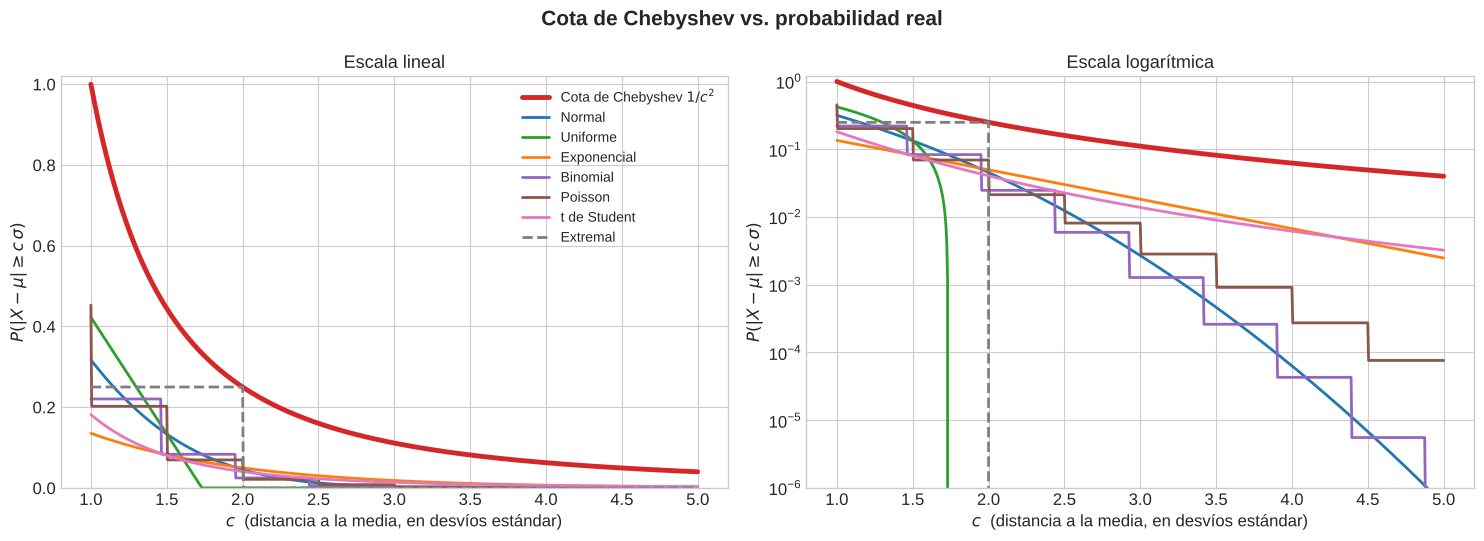

In [4]:
c = np.linspace(1, 5, 801)
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, log in zip(axs, [False, True]):
    ax.plot(c, 1 / c**2, color=COLORES['Chebyshev'], lw=3.5, label='Cota de Chebyshev $1/c^2$')
    for nombre, p in FAMILIAS.items():
        estilo = '--' if nombre == 'Extremal' else '-'
        ax.plot(c, p(c), estilo, color=COLORES[nombre], lw=2, label=nombre)
    ax.set_xlabel('$c$  (distancia a la media, en desvíos estándar)')
    ax.set_ylabel(r'$P(|X-\mu| \geq c\,\sigma)$')
    if log:
        ax.set_yscale('log')
        ax.set_ylim(1e-6, 1.2)
        ax.set_title('Escala logarítmica')
    else:
        ax.set_ylim(0, 1.02)
        ax.set_title('Escala lineal')
axs[0].legend(loc='upper right', fontsize=10)
fig.suptitle('Cota de Chebyshev vs. probabilidad real', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Observaciones
- **Todas** las curvas quedan por debajo de la roja: Chebyshev nunca falla.
- En escala logarítmica, la normal cae como $e^{-c^2/2}$, la exponencial como $e^{-c}$, y la $t_3$ como una potencia $c^{-3}$. La cota cae como $c^{-2}$: más lento que todas. **Cuanto más pesada la cola, más despacio se separa la curva de la cota** (pero eso no quiere decir que se acerque: lo vemos en 1.6).
- La uniforme desaparece del gráfico logarítmico en $c=\sqrt3$: después de ese punto su probabilidad es exactamente cero.
- Las discretas (binomial y Poisson) son **escalonadas**: $p(c)$ solo cambia cuando $\mu \pm c\sigma$ cruza un entero.

### 1.4 ¿Dónde está esa probabilidad? Las colas a $c = 2$
Para cada distribución pintamos la región $|X-\mu| \ge 2\sigma$. La cota de Chebyshev para esa región es siempre $1/4 = 0.25$.

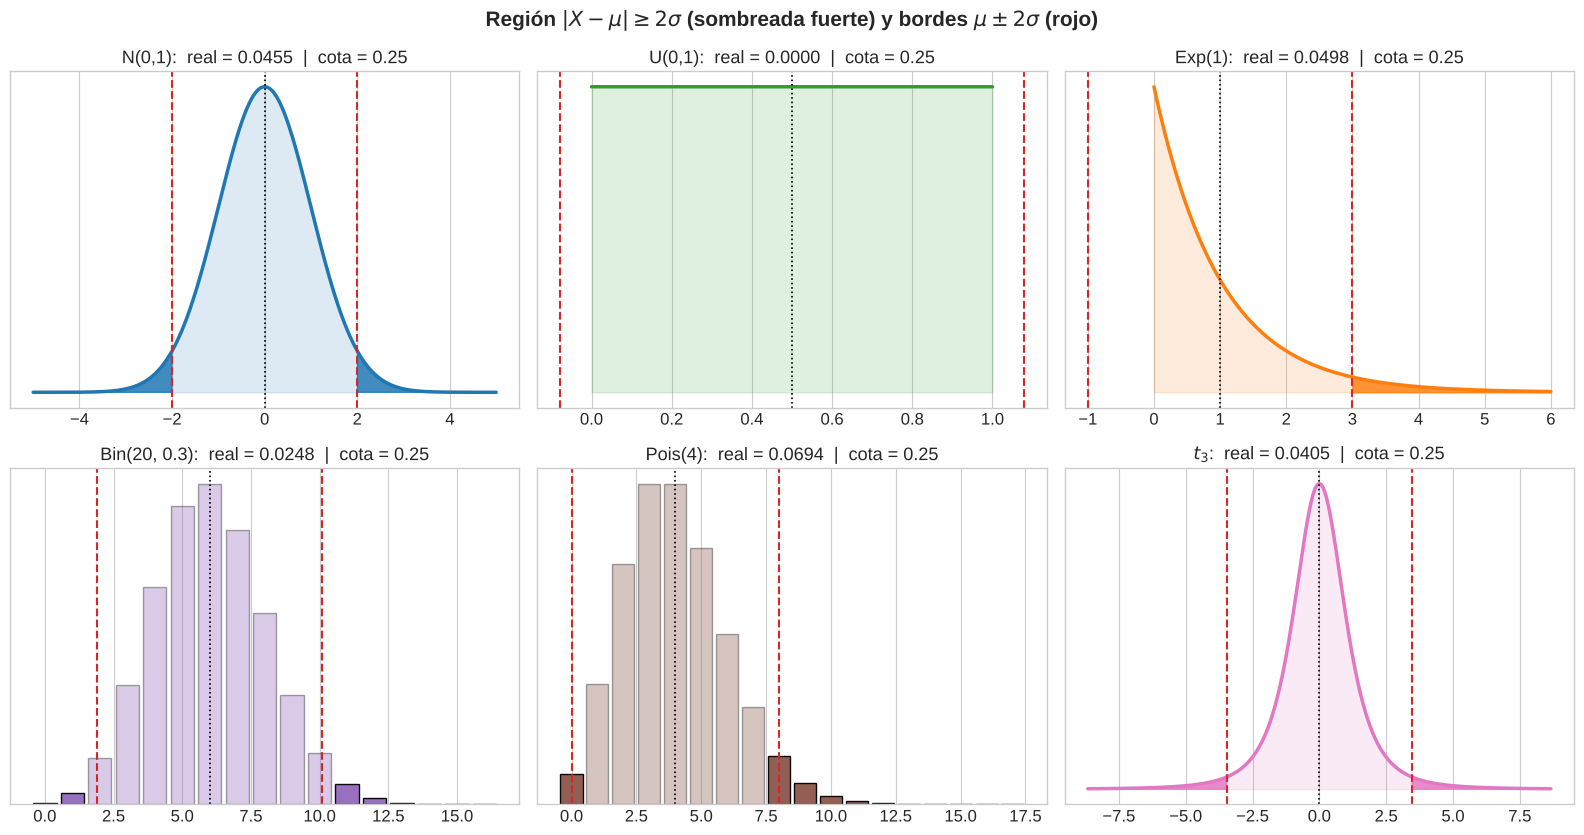

In [5]:
c0 = 2
paneles = [
    ('Normal', stats.norm()), ('Uniforme', stats.uniform()), ('Exponencial', stats.expon()),
    ('Binomial', stats.binom(20, 0.3)), ('Poisson', stats.poisson(4)), ('t de Student', stats.t(3)),
]
titulos = {'Normal': 'N(0,1)', 'Uniforme': 'U(0,1)', 'Exponencial': 'Exp(1)',
           'Binomial': 'Bin(20, 0.3)', 'Poisson': 'Pois(4)', 't de Student': '$t_3$'}
fig, axs = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (nombre, d) in zip(axs.flat, paneles):
    mu, s = d.mean(), d.std()
    col = COLORES[nombre]
    if hasattr(d.dist, 'pmf'):
        k = np.arange(int(d.ppf(1e-6)), int(d.isf(1e-6)) + 1)
        en_cola = np.abs(k - mu) >= c0 * s - TOL
        ax.bar(k[~en_cola], d.pmf(k[~en_cola]), color=col, alpha=0.35, edgecolor='black', width=0.85)
        ax.bar(k[en_cola], d.pmf(k[en_cola]), color=col, alpha=0.95, edgecolor='black', width=0.85)
    else:
        a, b = d.support()
        x = np.linspace(max(a, mu - 5 * s), min(b, mu + 5 * s), 1500)
        f = d.pdf(x)
        ax.plot(x, f, color=col, lw=2.5)
        ax.fill_between(x, f, where=np.abs(x - mu) < c0 * s, color=col, alpha=0.15)
        ax.fill_between(x, f, where=np.abs(x - mu) >= c0 * s, color=col, alpha=0.85)
    for borde in [mu - c0 * s, mu + c0 * s]:
        ax.axvline(borde, color=COLORES['Chebyshev'], ls='--', lw=1.5)
    ax.axvline(mu, color='black', ls=':', lw=1.2)
    p_real = float(FAMILIAS[nombre](c0))
    ax.set_title(f'{titulos[nombre]}:  real = {p_real:.4f}  |  cota = {1/c0**2:.2f}')
    ax.set_yticks([])
fig.suptitle(r'Región $|X-\mu| \geq 2\sigma$ (sombreada fuerte) y bordes $\mu \pm 2\sigma$ (rojo)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Fijate que...
- En la **uniforme** los bordes $\mu \pm 2\sigma$ caen **fuera** del soporte: no hay nada que pintar, la probabilidad es cero.
- En la **exponencial** toda la masa de la región está a la derecha: la cola izquierda no existe porque $\mu - 2\sigma = -1 < 0$. Chebyshev no "sabe" esto; suma las dos colas igual.
- En la **binomial** y la **Poisson** importa si los bordes caen justo sobre un entero o no: por eso las curvas de 1.3 son escalonadas.

### 1.5 ¿Se puede mejorar la cota? La distribución extremal
Que la cota sea floja para todas las distribuciones "conocidas" podría hacer pensar que $1/c^2$ es un mal número y que se podría poner algo más chico. **No se puede**, y la razón es que existe una distribución donde la igualdad se cumple.

Fijado $c_0 > 1$, definimos $X$ con
$$
P(X = -c_0) = P(X = c_0) = \frac{1}{2c_0^2}, \qquad P(X = 0) = 1 - \frac{1}{c_0^2}.
$$
Entonces $E(X) = 0$ por simetría y
$$
\text{Var}(X) = E(X^2) = c_0^2 \cdot \frac{1}{c_0^2} = 1,
$$
de modo que $\sigma = 1$ y
$$
P(|X - \mu| \ge c_0\,\sigma) = P(|X| \ge c_0) = \frac{1}{c_0^2}. \quad \text{¡Igualdad!}
$$

**Moraleja:** una cota que solo usa $\mu$ y $\sigma$ no puede ser mejor que $1/c^2$, porque esta $X$ tiene esos mismos $\mu$ y $\sigma$ y alcanza el valor. La flojedad de Chebyshev no es un defecto de la demostración: es el precio de no mirar la forma de la distribución.

#### 🧠 ¿Por qué esta distribución?
Mirá la demostración de Chebyshev: tiene dos desigualdades. La primera tira la parte de la integral donde $|x-\mu| < k$; la segunda reemplaza $(x-\mu)^2$ por $k^2$ en la región restante. Para que **ninguna** pierda nada, la masa tiene que estar o justo en $\mu$ (donde aporta cero a la varianza) o justo a distancia $k$. Eso es exactamente la extremal.

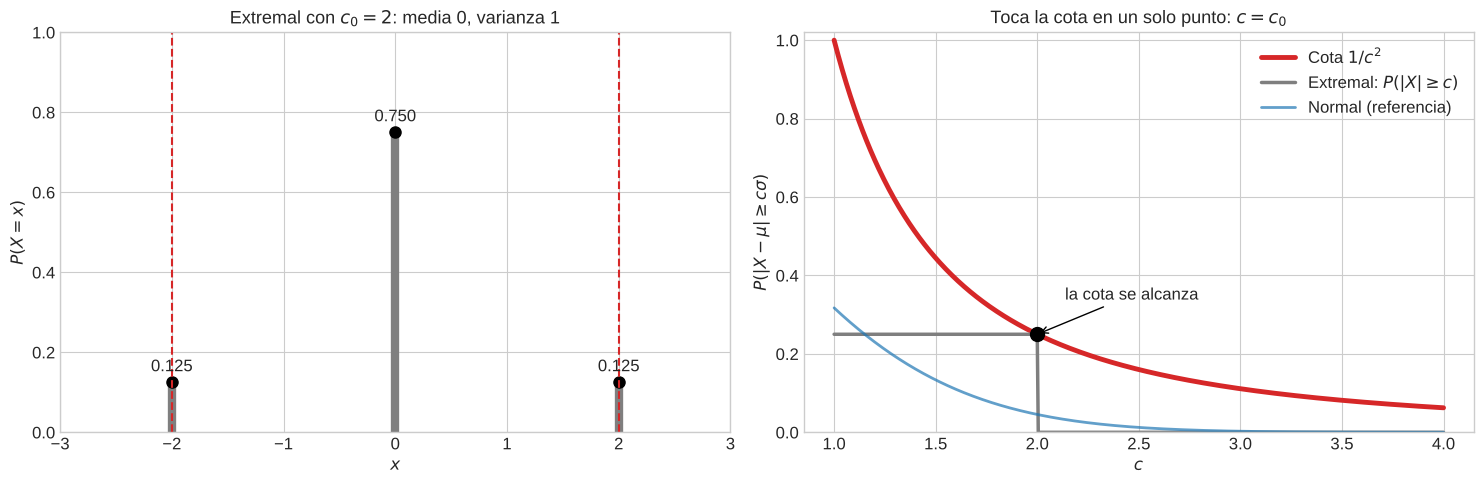

In [6]:
c0 = 2.0
c = np.linspace(1, 4, 601)
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
# Izquierda: la función de probabilidad puntual
xs = np.array([-c0, 0, c0])
ps = np.array([1 / (2 * c0**2), 1 - 1 / c0**2, 1 / (2 * c0**2)])
axs[0].vlines(xs, 0, ps, color=COLORES['Extremal'], lw=6)
axs[0].plot(xs, ps, 'o', color='black', ms=8)
for x_, p_ in zip(xs, ps):
    axs[0].annotate(f'{p_:.3f}', (x_, p_), textcoords='offset points', xytext=(0, 8), ha='center')
axs[0].axvline(-c0, color=COLORES['Chebyshev'], ls='--'); axs[0].axvline(c0, color=COLORES['Chebyshev'], ls='--')
axs[0].set_xlim(-3, 3); axs[0].set_ylim(0, 1)
axs[0].set_xlabel('$x$'); axs[0].set_ylabel('$P(X = x)$')
axs[0].set_title(f'Extremal con $c_0 = {c0:g}$: media 0, varianza 1')
# Derecha: p(c) vs cota
axs[1].plot(c, 1 / c**2, color=COLORES['Chebyshev'], lw=3.5, label='Cota $1/c^2$')
axs[1].plot(c, p_extremal(c0, c), color=COLORES['Extremal'], lw=2.5, label='Extremal: $P(|X| \\geq c)$')
axs[1].plot(c, FAMILIAS['Normal'](c), color=COLORES['Normal'], lw=2, alpha=0.7, label='Normal (referencia)')
axs[1].plot([c0], [1 / c0**2], 'o', color='black', ms=10, zorder=5)
axs[1].annotate('la cota se alcanza', (c0, 1 / c0**2), textcoords='offset points', xytext=(20, 25),
                arrowprops=dict(arrowstyle='->'))
axs[1].set_xlabel('$c$'); axs[1].set_ylabel(r'$P(|X-\mu| \geq c\sigma)$')
axs[1].set_ylim(0, 1.02); axs[1].legend()
axs[1].set_title('Toca la cota en un solo punto: $c = c_0$')
plt.tight_layout()
plt.show()

#### 🔎 Ojo con la lectura
La extremal toca la cota **solo en $c = c_0$**. Para otros $c$ queda por debajo (como todas). No existe una única distribución que alcance la cota para todos los $c$ a la vez, pero **para cada $c$ hay una** que la alcanza. Eso alcanza para decir que $1/c^2$ es la mejor cota posible usando solo $\mu$ y $\sigma$.

### 1.6 Colas pesadas: la t de Student
La $t_\nu$ tiene varianza finita solo si $\nu > 2$, y en ese caso $\sigma^2 = \nu/(\nu-2)$. Para $\nu \le 2$ **Chebyshev no se puede aplicar**: no hay $\sigma$ finito.

Uno esperaría que, al bajar $\nu$ hacia 2 y engordar las colas, $p(c)$ se acerque a la cota. **Veamos si es así.** A la derecha usamos escala **log-log**: ahí una potencia $c^{-a}$ es una recta de pendiente $-a$.

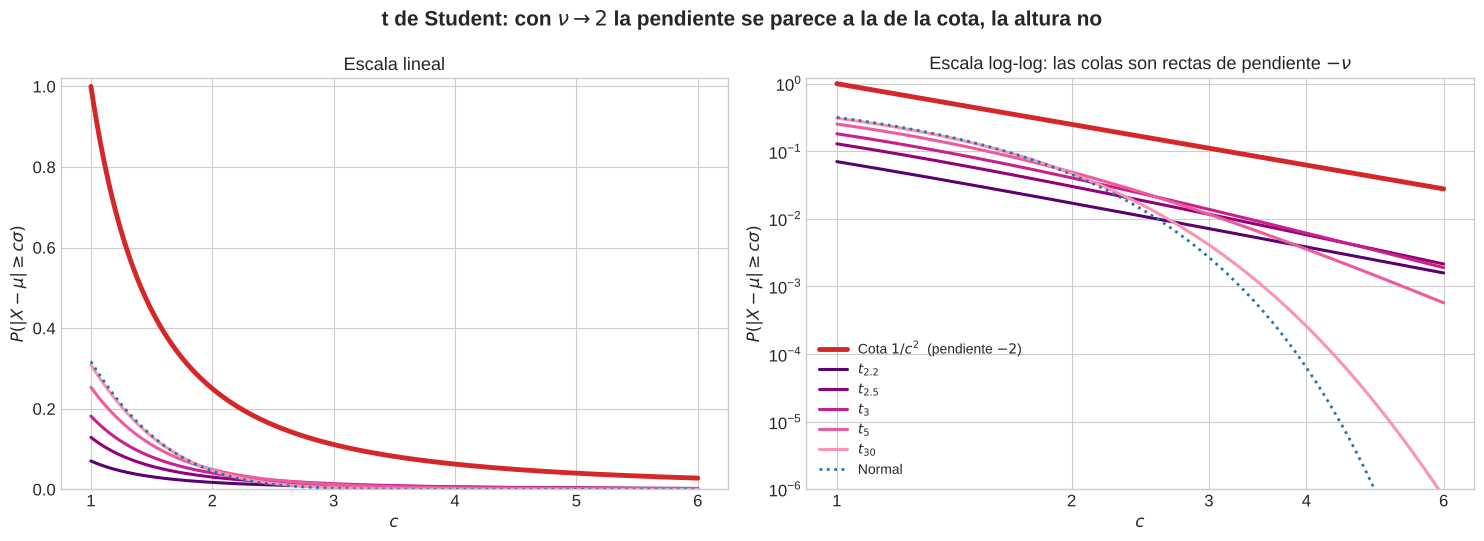

In [7]:
c = np.linspace(1, 6, 801)
nus = [2.2, 2.5, 3, 5, 30]
tonos = plt.cm.RdPu(np.linspace(0.95, 0.4, len(nus)))
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, log in zip(axs, [False, True]):
    ax.plot(c, 1 / c**2, color=COLORES['Chebyshev'], lw=3.5, label='Cota $1/c^2$  (pendiente $-2$)')
    for nu, tono in zip(nus, tonos):
        ax.plot(c, p_continua(stats.t(nu), c), color=tono, lw=2.2, label=f'$t_{{{nu:g}}}$')
    ax.plot(c, FAMILIAS['Normal'](c), color=COLORES['Normal'], ls=':', lw=2, label='Normal')
    ax.set_xlabel('$c$'); ax.set_ylabel(r'$P(|X-\mu| \geq c\sigma)$')
    if log:
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-6, 1.2)
        ax.set_xticks([1, 2, 3, 4, 6]); ax.set_xticklabels(['1', '2', '3', '4', '6'])
        ax.set_title('Escala log-log: las colas son rectas de pendiente $-\\nu$')
    else:
        ax.set_ylim(0, 1.02); ax.set_title('Escala lineal')
axs[1].legend(loc='lower left', fontsize=10)
fig.suptitle('t de Student: con $\\nu \\to 2$ la pendiente se parece a la de la cota, la altura no',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Observación
Pasan dos cosas a la vez:
- **La pendiente:** la cola de la $t_\nu$ cae como $c^{-\nu}$. Con $\nu = 2.2$ la recta tiene pendiente $-2.2$, casi paralela a la cota. Colas más pesadas hacen que la curva **se separe de la cota más despacio**.
- **La altura:** pero $\sigma^2 = \nu/(\nu-2)$ explota (con $\nu = 2.2$, $\sigma \approx 3.3$). El umbral $c\sigma$ se va muy lejos y casi toda la masa queda adentro. Por eso, para $c$ chico, la $t_{2.2}$ está **por debajo** de la normal.

**Conclusión:** engordar las colas no alcanza para acercarse a la cota. Para tocarla hace falta algo como la extremal: masa concentrada en la media y el resto puesto justo en el borde. Con $\nu = 30$, en cambio, la $t$ ya es prácticamente una normal.

### 1.7 🎛️ Explorá vos: elegí la distribución, los parámetros y $c$
- **Izquierda:** la distribución con la región $|X-\mu| \ge c\sigma$ sombreada.
- **Derecha:** la curva $p(c)$ completa, la cota, y el punto donde estás parado.

Solo aparecen los *sliders* que corresponden a la familia elegida.

**Para probar:**
- Binomial con $p$ muy chico ($p = 0.02$): ¿qué pasa con la asimetría y con la cota?
- Poisson con $\lambda = 0.5$ y con $\lambda = 50$.
- t de Student con $\nu$ apenas mayor que 2: ¿se acerca a la cota? Mirá cuánto vale $\sigma$.
- Extremal: movés $c$ hasta $c_0$ y ves el momento exacto en que la cota se cumple con igualdad.

In [8]:
def construir(familia, n, p, lam, nu, c0):
    if familia == 'Normal':       return stats.norm(), 'N(0,1)'
    if familia == 'Uniforme':     return stats.uniform(), 'U(0,1)'
    if familia == 'Exponencial':  return stats.expon(), 'Exp(1)'
    if familia == 'Binomial':     return stats.binom(n, p), f'Bin({n}, {p:.2f})'
    if familia == 'Poisson':      return stats.poisson(lam), f'Pois({lam:g})'
    if familia == 't de Student': return stats.t(nu), f't con ν = {nu:g}'
    return None, f'Extremal, c₀ = {c0:g}'

def p_de(familia, d, c0, c):
    if familia == 'Extremal':
        return p_extremal(c0, c)
    return p_discreta(d, c) if hasattr(d.dist, 'pmf') else p_continua(d, c)

def lab_chebyshev(familia, c, n, p, lam, nu, c0):
    d, etiqueta = construir(familia, n, p, lam, nu, c0)
    col = COLORES[familia]
    grilla_c = np.linspace(1, 6, 801)
    p_c = float(p_de(familia, d, c0, c))
    cota = 1 / c**2
    fig, axs = plt.subplots(1, 2, figsize=(15, 5.2))
    # --- Izquierda: distribución y región sombreada
    if familia == 'Extremal':
        mu, s = 0.0, 1.0
        xs = np.array([-c0, 0, c0]); ps = np.array([1/(2*c0**2), 1 - 1/c0**2, 1/(2*c0**2)])
        en_cola = np.abs(xs) >= c * s - TOL
        axs[0].vlines(xs[~en_cola], 0, ps[~en_cola], color=col, lw=7, alpha=0.35)
        axs[0].vlines(xs[en_cola], 0, ps[en_cola], color=col, lw=7, alpha=0.95)
        axs[0].set_xlim(-max(c0, c) - 1, max(c0, c) + 1)
    elif hasattr(d.dist, 'pmf'):
        mu, s = d.mean(), d.std()
        k = np.arange(int(d.ppf(1e-6)), int(d.isf(1e-6)) + 1)
        en_cola = np.abs(k - mu) >= c * s - TOL
        axs[0].bar(k[~en_cola], d.pmf(k[~en_cola]), color=col, alpha=0.35, edgecolor='black', width=0.85)
        axs[0].bar(k[en_cola], d.pmf(k[en_cola]), color=col, alpha=0.95, edgecolor='black', width=0.85)
    else:
        mu, s = d.mean(), d.std()
        a, b = d.support()
        ancho = max(5, c + 1) * s
        x = np.linspace(max(a, mu - ancho), min(b, mu + ancho), 2000)
        f = d.pdf(x)
        axs[0].plot(x, f, color=col, lw=2.5)
        axs[0].fill_between(x, f, where=np.abs(x - mu) < c * s, color=col, alpha=0.15)
        axs[0].fill_between(x, f, where=np.abs(x - mu) >= c * s, color=col, alpha=0.85)
    for borde in [mu - c * s, mu + c * s]:
        axs[0].axvline(borde, color=COLORES['Chebyshev'], ls='--', lw=1.8)
    axs[0].axvline(mu, color='black', ls=':', lw=1.2)
    axs[0].set_title(f'{etiqueta}:   μ = {mu:.3g},  σ = {s:.3g}')
    axs[0].set_yticks([])
    # --- Derecha: curva p(c) y cota
    axs[1].plot(grilla_c, 1 / grilla_c**2, color=COLORES['Chebyshev'], lw=3.5, label='Cota $1/c^2$')
    axs[1].plot(grilla_c, p_de(familia, d, c0, grilla_c), color=col, lw=2.5, label=etiqueta)
    axs[1].plot([c], [cota], 'o', color=COLORES['Chebyshev'], ms=10)
    axs[1].plot([c], [p_c], 'o', color='black', ms=10)
    axs[1].vlines(c, p_c, cota, color='gray', ls=':', lw=2)
    axs[1].set_ylim(0, 1.02); axs[1].set_xlabel('$c$'); axs[1].set_ylabel(r'$P(|X-\mu| \geq c\sigma)$')
    axs[1].legend(loc='upper right')
    exagera = f'{cota / p_c:.1f}×' if p_c > 0 else '∞ (prob. real = 0)'
    axs[1].set_title(f'c = {c:.2f}:   real = {p_c:.4f}   cota = {cota:.4f}   exagera {exagera}')
    plt.tight_layout()
    plt.show()

# --- Controles
w_fam = widgets.Dropdown(options=list(FAMILIAS.keys()), value='Binomial', description='Familia')
w_c   = widgets.FloatSlider(value=2.0, min=1.0, max=5.0, step=0.05, description='c', continuous_update=False)
w_n   = widgets.IntSlider(value=20, min=2, max=200, step=1, description='n', continuous_update=False)
w_p   = widgets.FloatSlider(value=0.3, min=0.01, max=0.99, step=0.01, description='p', continuous_update=False)
w_lam = widgets.FloatSlider(value=4.0, min=0.2, max=60, step=0.1, description='λ', continuous_update=False)
w_nu  = widgets.FloatSlider(value=3.0, min=2.05, max=30, step=0.05, description='ν', continuous_update=False)
w_c0  = widgets.FloatSlider(value=2.0, min=1.05, max=5.0, step=0.05, description='c₀', continuous_update=False)
PARAMETROS = {'Binomial': [w_n, w_p], 'Poisson': [w_lam], 't de Student': [w_nu], 'Extremal': [w_c0]}

def mostrar_sliders(*_):
    for w in [w_n, w_p, w_lam, w_nu, w_c0]:
        w.layout.display = 'flex' if w in PARAMETROS.get(w_fam.value, []) else 'none'
w_fam.observe(mostrar_sliders, names='value')
mostrar_sliders()

salida = widgets.interactive_output(lab_chebyshev, dict(familia=w_fam, c=w_c, n=w_n, p=w_p, lam=w_lam, nu=w_nu, c0=w_c0))
display(widgets.VBox([widgets.HBox([w_fam, w_c]), widgets.HBox([w_n, w_p, w_lam, w_nu, w_c0]), salida]))

### 1.8 Para cerrar la Parte 1
- Chebyshev **siempre** se cumple, para cualquier distribución con varianza finita.
- Para las distribuciones usuales es **muy conservadora**: entre 5 y 40 veces más grande que el valor real con $c$ entre 2 y 3 para la normal, y puede valer algo positivo cuando la probabilidad real es cero (uniforme).
- **No se puede mejorar** sin más información: la distribución extremal la alcanza.
- Las colas pesadas hacen que la cota se separe más despacio del valor real, pero no la alcanzan: eso requiere una forma muy particular, como la extremal.

**Preguntas para pensar**
1. Si solo sabés que $\mu = 10$ y $\sigma = 2$, ¿qué podés afirmar sobre $P(4 < X < 16)$? ¿Y si además sabés que $X$ es normal?
2. En la exponencial, ¿por qué para $c \ge 1$ toda la probabilidad $p(c)$ está en una sola cola? ¿Chebyshev se entera de eso?
3. En la extremal con $c_0 = 3$, ¿cuánto vale $P(X = 0)$? ¿Qué pasa con esa distribución cuando $c_0 \to \infty$?

En la Parte 4 vamos a usar Chebyshev aplicada al **promedio** $\overline X_n$, que es justamente como se demuestra la ley débil, y la vamos a comparar con lo que da el TCL.

---
# 🟣 PARTE 2: Aproximaciones a la binomial y a la Poisson

### 2.1 Las tres aproximaciones que vamos a probar

| Aproximación | Se escribe | De dónde sale | Regla práctica usual |
|---|---|---|---|
| Normal → Binomial | $\text{Bin}(n,p) \;\dot\sim\; N\big(np,\ np(1-p)\big)$ | TCL: suma de $n$ Bernoulli | $np \ge 5$ y $n(1-p) \ge 5$ (o $\ge 10$) |
| Normal → Poisson | $\text{Pois}(\lambda) \;\dot\sim\; N(\lambda,\ \lambda)$ | TCL: suma de Poisson chicas | $\lambda \ge 10$ |
| Poisson → Binomial | $\text{Bin}(n,p) \;\dot\sim\; \text{Pois}(np)$ | Eventos raros: $n \to \infty$, $p \to 0$, $np \to \lambda$ | $n \ge 20$ y $p \le 0.05$ |

Las dos primeras usan **corrección por continuidad (CC)**: como la variable es entera, $P(X \le k)$ se aproxima por $\Phi\!\left(\frac{k + 0.5 - \mu}{\sigma}\right)$ en lugar de $\Phi\!\left(\frac{k - \mu}{\sigma}\right)$.

#### 📏 ¿Cómo medimos el error?
Usamos dos medidas:
1. **Error en una probabilidad concreta**, por ejemplo $P(50 \le X \le 70)$: es lo que importa cuando resolvés un ejercicio.
2. **Error máximo sobre la acumulada:**
$$
D = \max_{k} \big|F_{\text{exacta}}(k) - F_{\text{aprox}}(k)\big|.
$$
Es el peor error que podés cometer al aproximar **cualquier** probabilidad del tipo $P(X \le k)$. Si $D = 0.01$, ninguna de esas probabilidades se equivoca en más de un punto porcentual.

In [9]:
# Acumuladas exactas y aproximadas, y el error máximo D
def F_normal(k, mu, sigma, cc=True):
    return stats.norm.cdf(np.asarray(k) + (0.5 if cc else 0.0), mu, sigma)

def D_binom_normal(n, p, cc=True):
    k = np.arange(0, n + 1)
    return np.max(np.abs(stats.binom.cdf(k, n, p) - F_normal(k, n * p, np.sqrt(n * p * (1 - p)), cc)))

def D_binom_poisson(n, p):
    k = np.arange(0, n + 1)
    return np.max(np.abs(stats.binom.cdf(k, n, p) - stats.poisson.cdf(k, n * p)))

def D_poisson_normal(lam, cc=True):
    k = np.arange(0, int(stats.poisson.isf(1e-12, lam)) + 2)
    return np.max(np.abs(stats.poisson.cdf(k, lam) - F_normal(k, lam, np.sqrt(lam), cc)))

print(f"Ejemplo: Bin(20, 0.3)  ->  D con CC = {D_binom_normal(20, 0.3):.4f},  sin CC = {D_binom_normal(20, 0.3, cc=False):.4f}")

Ejemplo: Bin(20, 0.3)  ->  D con CC = 0.0127,  sin CC = 0.1080


### 2.2 Normal → Binomial: mirá la forma
Seis binomiales con la normal de igual media y varianza superpuesta. En el título: $np$, $n(1-p)$ y el error máximo $D$ con y sin corrección por continuidad.

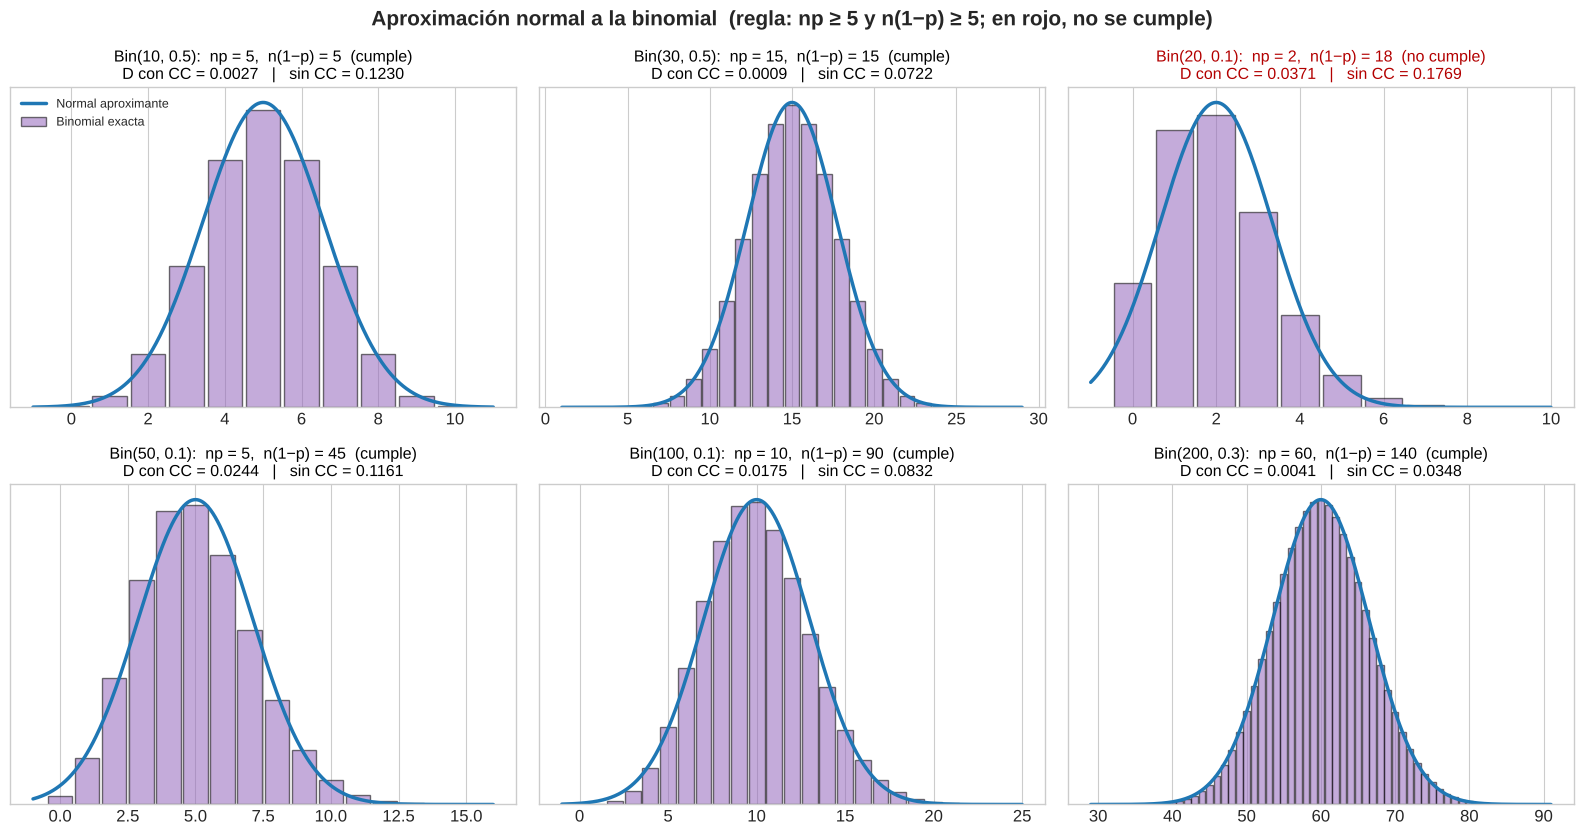

In [10]:
casos = [(10, 0.5), (30, 0.5), (20, 0.1), (50, 0.1), (100, 0.1), (200, 0.3)]
fig, axs = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (n, p) in zip(axs.flat, casos):
    mu, s = n * p, np.sqrt(n * p * (1 - p))
    k = np.arange(max(0, int(mu - 4.5 * s)), min(n, int(mu + 4.5 * s) + 1) + 1)
    ax.bar(k, stats.binom.pmf(k, n, p), color=COLORES['Binomial'], alpha=0.55, edgecolor='black', width=0.9,
           label='Binomial exacta')
    x = np.linspace(k[0] - 1, k[-1] + 1, 600)
    ax.plot(x, stats.norm.pdf(x, mu, s), color=COLORES['Normal'], lw=2.5, label='Normal aproximante')
    cumple = (n * p >= 5) and (n * (1 - p) >= 5)
    marca = '(cumple)' if cumple else '(no cumple)'
    ax.set_title(f'Bin({n}, {p}):  np = {n*p:g},  n(1−p) = {n*(1-p):g}  {marca}\n'
                 f'D con CC = {D_binom_normal(n, p):.4f}   |   sin CC = {D_binom_normal(n, p, False):.4f}',
                 fontsize=11.5, color='black' if cumple else '#b30000')
    ax.set_yticks([])
axs[0, 0].legend(loc='upper left', fontsize=9)
fig.suptitle('Aproximación normal a la binomial  (regla: np ≥ 5 y n(1−p) ≥ 5; en rojo, no se cumple)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Fijate que...
- Con $p = 0.5$ la binomial es **simétrica** y la normal anda bien incluso con $n = 10$.
- Con $p = 0.1$ y $n = 20$ ($np = 2$) la binomial está **pegada al cero y torcida a la derecha**: la normal le asigna probabilidad a valores negativos y erra la moda.
- La corrección por continuidad **siempre** baja el error, en general a menos de la mitad. No es un detalle: es la mitad del trabajo.

### 2.3 ¿Por qué funciona la corrección por continuidad?
Cada barra de la binomial está centrada en un entero $k$ y tiene ancho 1: ocupa el intervalo $[k - 0.5,\ k + 0.5]$. Entonces $P(X \le 5)$ es el área de las barras hasta la del 5 **inclusive**, que termina en $5.5$, no en $5$.

Sin corrección, cortamos la normal en $5$ y nos comemos media barra.

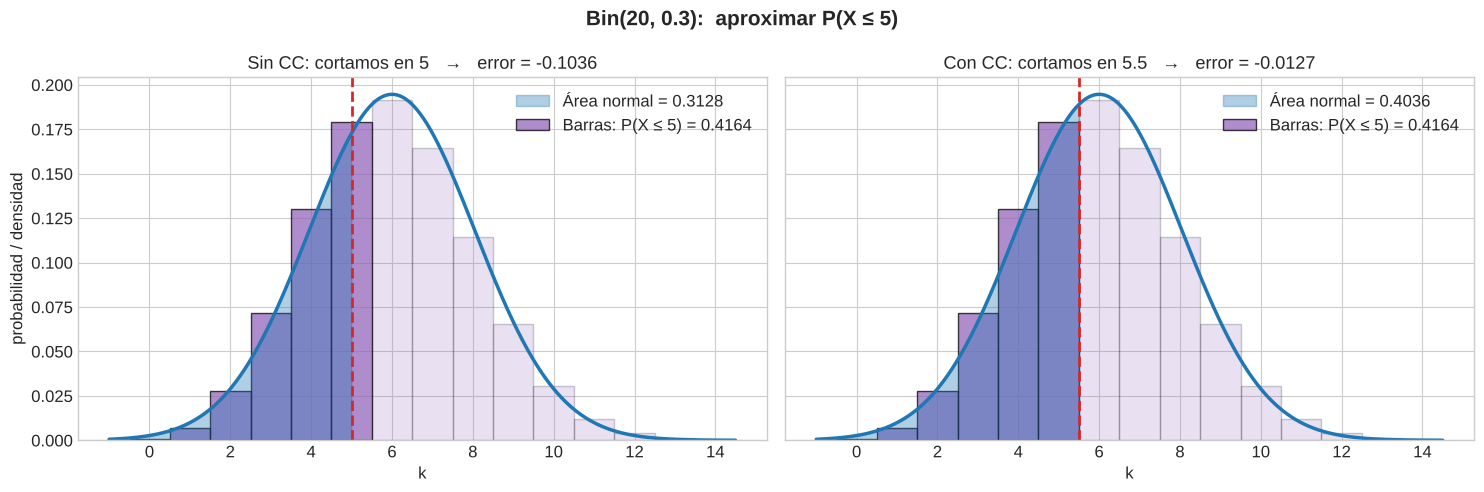

In [11]:
n, p, k0 = 20, 0.3, 5
mu, s = n * p, np.sqrt(n * p * (1 - p))
exacta = stats.binom.cdf(k0, n, p)
con_cc, sin_cc = F_normal(k0, mu, s, True), F_normal(k0, mu, s, False)
k = np.arange(0, 15)
x = np.linspace(-1, 14.5, 800)
fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, corte, titulo, valor in [(axs[0], k0, f'Sin CC: cortamos en {k0}', sin_cc),
                                 (axs[1], k0 + 0.5, f'Con CC: cortamos en {k0}.5', con_cc)]:
    ax.bar(k[k <= k0], stats.binom.pmf(k[k <= k0], n, p), width=1.0, color=COLORES['Binomial'],
           alpha=0.75, edgecolor='black', label=f'Barras: P(X ≤ {k0}) = {exacta:.4f}')
    ax.bar(k[k > k0], stats.binom.pmf(k[k > k0], n, p), width=1.0, color=COLORES['Binomial'],
           alpha=0.2, edgecolor='black')
    ax.plot(x, stats.norm.pdf(x, mu, s), color=COLORES['Normal'], lw=2.5)
    ax.fill_between(x, stats.norm.pdf(x, mu, s), where=x <= corte, color=COLORES['Normal'], alpha=0.35,
                    label=f'Área normal = {valor:.4f}')
    ax.axvline(corte, color=COLORES['Chebyshev'], ls='--', lw=2)
    ax.set_title(f'{titulo}   →   error = {valor - exacta:+.4f}')
    ax.set_xlabel('k'); ax.legend(loc='upper right')
axs[0].set_ylabel('probabilidad / densidad')
fig.suptitle(f'Bin({n}, {p}):  aproximar P(X ≤ {k0})', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### ✍️ Los ejemplos de la Clase 18, con el valor exacto al lado

In [12]:
def fila(nombre, exacta, cc, sin):
    return {'Ejemplo': nombre, 'Exacta': exacta, 'Normal con CC': cc, 'Normal sin CC': sin,
            'Error rel. con CC': (cc - exacta) / exacta, 'Error rel. sin CC': (sin - exacta) / exacta}

N = stats.norm.cdf
s1 = np.sqrt(42); s2 = np.sqrt(15.3); s3 = np.sqrt(50)
ejemplos = pd.DataFrame([
    fila('Bin(200, 0.3):  P(50 ≤ X ≤ 70)',
         stats.binom.cdf(70, 200, .3) - stats.binom.cdf(49, 200, .3),
         N((70.5 - 60) / s1) - N((49.5 - 60) / s1), N((70 - 60) / s1) - N((50 - 60) / s1)),
    fila('Bin(120, 0.85):  P(X < 95)',
         stats.binom.cdf(94, 120, .85), N((94.5 - 102) / s2), N((95 - 102) / s2)),
    fila('Pois(50):  P(X > 60)',
         stats.poisson.sf(60, 50), 1 - N((60.5 - 50) / s3), 1 - N((60 - 50) / s3)),
]).set_index('Ejemplo')
display(ejemplos.style.format({'Exacta': '{:.4f}', 'Normal con CC': '{:.4f}', 'Normal sin CC': '{:.4f}',
                               'Error rel. con CC': '{:+.1%}', 'Error rel. sin CC': '{:+.1%}'}))

,Exacta,Normal con CC,Normal sin CC,Error rel. con CC,Error rel. sin CC
Ejemplo,,,,,
"Bin(200, 0.3): P(50 ≤ X ≤ 70)",0.8952,0.8948,0.8772,-0.0%,-2.0%
"Bin(120, 0.85): P(X < 95)",0.0320,0.0276,0.0368,-13.8%,+14.8%
Pois(50): P(X > 60),0.0722,0.0688,0.0786,-4.7%,+9.0%


#### 🔎 Lectura
- En el primer ejemplo ($p = 0.3$, $n = 200$) la aproximación con CC es casi exacta.
- En el segundo, $p = 0.85$ hace a la binomial **asimétrica** (cola larga a la izquierda) y estamos aproximando justo esa cola: aunque $n(1-p) = 18$ cumple holgado la regla, el error relativo es de casi $-14\%$. **La regla mira el centro, no las colas.**
- En el tercero, la aproximación normal da $0.069$ y el valor exacto es $0.072$: subestima un poco la cola derecha, porque la Poisson es asimétrica a la derecha.
- Sin CC el error empeora mucho en el primero y en el tercero. En el segundo, la CC no mejora la magnitud: solo cambia el signo del error. Cuando el problema es la asimetría, la CC no lo arregla.

### 2.4 Poniendo a prueba la regla $np \ge 5$
Graficamos el error máximo $D$ (con CC) en función de $np$, para varios valores de $p$. Si la regla capturara todo, las curvas deberían caer por debajo de un mismo nivel al cruzar $np = 5$.

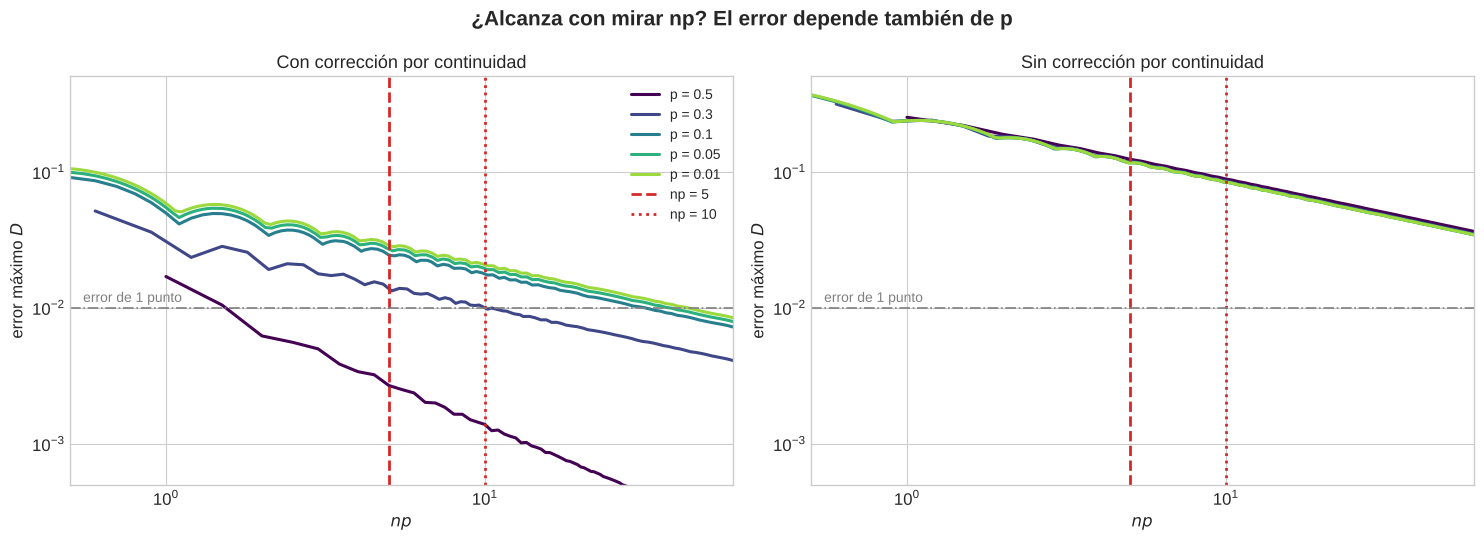

In [13]:
ps = [0.5, 0.3, 0.1, 0.05, 0.01]
tonos = plt.cm.viridis(np.linspace(0, 0.85, len(ps)))
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
for p, tono in zip(ps, tonos):
    ns = np.unique(np.round(np.geomspace(max(2, 0.5 / p), 60 / p, 120)).astype(int))
    np_ = ns * p
    axs[0].plot(np_, [D_binom_normal(n, p) for n in ns], color=tono, lw=2.2, label=f'p = {p}')
    axs[1].plot(np_, [D_binom_normal(n, p, cc=False) for n in ns], color=tono, lw=2.2, label=f'p = {p}')
for ax, titulo in zip(axs, ['Con corrección por continuidad', 'Sin corrección por continuidad']):
    ax.axvline(5, color=COLORES['Chebyshev'], ls='--', lw=2, label='np = 5')
    ax.axvline(10, color=COLORES['Chebyshev'], ls=':', lw=2, label='np = 10')
    ax.axhline(0.01, color='gray', ls='-.', lw=1.2)
    ax.text(0.55, 0.0105, 'error de 1 punto', color='gray', fontsize=10, va='bottom')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(0.5, 60); ax.set_ylim(5e-4, 0.5)
    ax.set_xlabel('$np$'); ax.set_ylabel('error máximo $D$'); ax.set_title(titulo)
axs[0].legend(loc='upper right', fontsize=10)
fig.suptitle('¿Alcanza con mirar np? El error depende también de p', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- Para un mismo $np$, el error es **menor cuanto más cerca de 0.5 está $p$**: con $p=0.5$ la binomial es simétrica y la normal le calza mejor. Con $p \le 0.1$, $np = 5$ deja un error de alrededor de **2 a 3 puntos**.
- Pasar de $np \ge 5$ a $np \ge 10$ mejora, pero no hace milagros: el error decrece lento, aproximadamente como $1/\sqrt{np}$ (en el gráfico log-log, una recta de pendiente $-1/2$). Con $p = 0.5$ cae más rápido: la binomial simétrica es un caso especial.
- Sin CC, todas las curvas suben bastante y **se juntan**: el error queda dominado por la media barra que se pierde, sin importar $p$. La corrección vale más que multiplicar $n$ por diez.

**Moraleja:** $np \ge 5$ no es un teorema, es un **acuerdo** sobre cuánto error estamos dispuestos a tolerar. Garantiza errores de unos pocos puntos, no de décimas.

### 2.5 Normal → Poisson
Si $X \sim \text{Pois}(\lambda)$, entonces $E(X) = \text{Var}(X) = \lambda$, y para $\lambda$ grande $X \;\dot\sim\; N(\lambda, \lambda)$. La regla usual pide $\lambda \ge 10$.

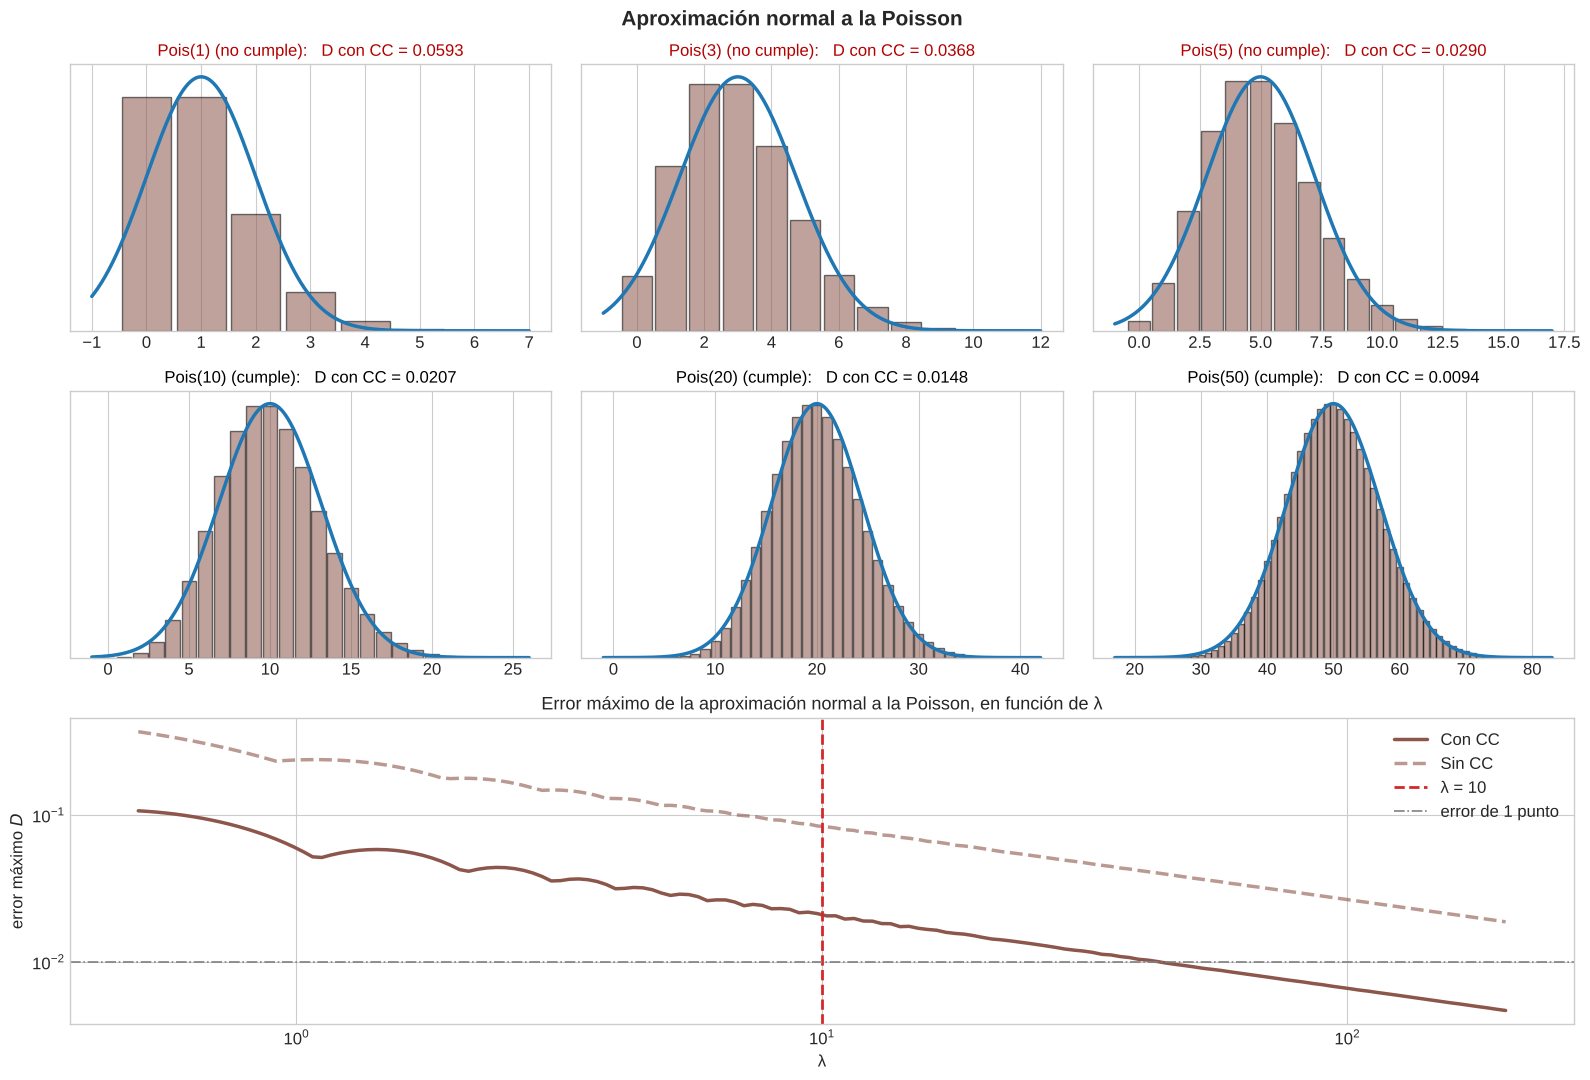

In [14]:
lams = [1, 3, 5, 10, 20, 50]
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1.15])
for i, lam in enumerate(lams):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    s = np.sqrt(lam)
    k = np.arange(max(0, int(lam - 4.5 * s)), int(lam + 4.5 * s) + 2)
    ax.bar(k, stats.poisson.pmf(k, lam), color=COLORES['Poisson'], alpha=0.55, edgecolor='black', width=0.9)
    x = np.linspace(k[0] - 1, k[-1] + 1, 600)
    ax.plot(x, stats.norm.pdf(x, lam, s), color=COLORES['Normal'], lw=2.5)
    cumple = lam >= 10
    ax.set_title(f'Pois({lam}) {"(cumple)" if cumple else "(no cumple)"}:   D con CC = {D_poisson_normal(lam):.4f}',
                 fontsize=12, color='black' if cumple else '#b30000')
    ax.set_yticks([])
ax = fig.add_subplot(gs[2, :])
grilla = np.geomspace(0.5, 200, 150)
ax.plot(grilla, [D_poisson_normal(l) for l in grilla], color=COLORES['Poisson'], lw=2.5, label='Con CC')
ax.plot(grilla, [D_poisson_normal(l, cc=False) for l in grilla], color=COLORES['Poisson'], lw=2.5, ls='--',
        alpha=0.6, label='Sin CC')
ax.axvline(10, color=COLORES['Chebyshev'], ls='--', lw=2, label='λ = 10')
ax.axhline(0.01, color='gray', ls='-.', lw=1.2, label='error de 1 punto')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('λ'); ax.set_ylabel('error máximo $D$'); ax.legend()
ax.set_title('Error máximo de la aproximación normal a la Poisson, en función de λ')
fig.suptitle('Aproximación normal a la Poisson', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- Con $\lambda = 1$ o $3$ la Poisson está pegada al cero y la normal no tiene chance.
- En $\lambda = 10$, con CC, el error máximo ronda los **2 puntos**; para bajar de 1 punto hace falta $\lambda$ del orden de 40.
- Otra vez la caída es como $1/\sqrt\lambda$: cuadruplicar $\lambda$ divide el error por dos.

> 📝 **Nota sobre la Clase 18.** En el ejemplo del *call center* ($\lambda = 50$, $P(X > 60)$), el valor exacto es $\approx 0.0722$ (calculado en la tabla de 2.3), y la aproximación con CC da $0.0688$.

### 2.6 Poisson → Binomial: los eventos raros
Cuando $n$ es grande y $p$ es chico, la binomial está pegada al cero y es muy asimétrica: la normal no sirve. Pero ahí aparece otra aproximación:
$$
\binom{n}{k} p^k (1-p)^{n-k} \;\longrightarrow\; e^{-\lambda} \frac{\lambda^k}{k!}, \qquad n \to \infty,\ p \to 0,\ np \to \lambda.
$$

Mantenemos fijo $np = 3$ y vamos achicando $p$ (es decir, agrandando $n$). En cada panel están las tres: binomial exacta (barras), Poisson (puntos) y normal con CC (curva).

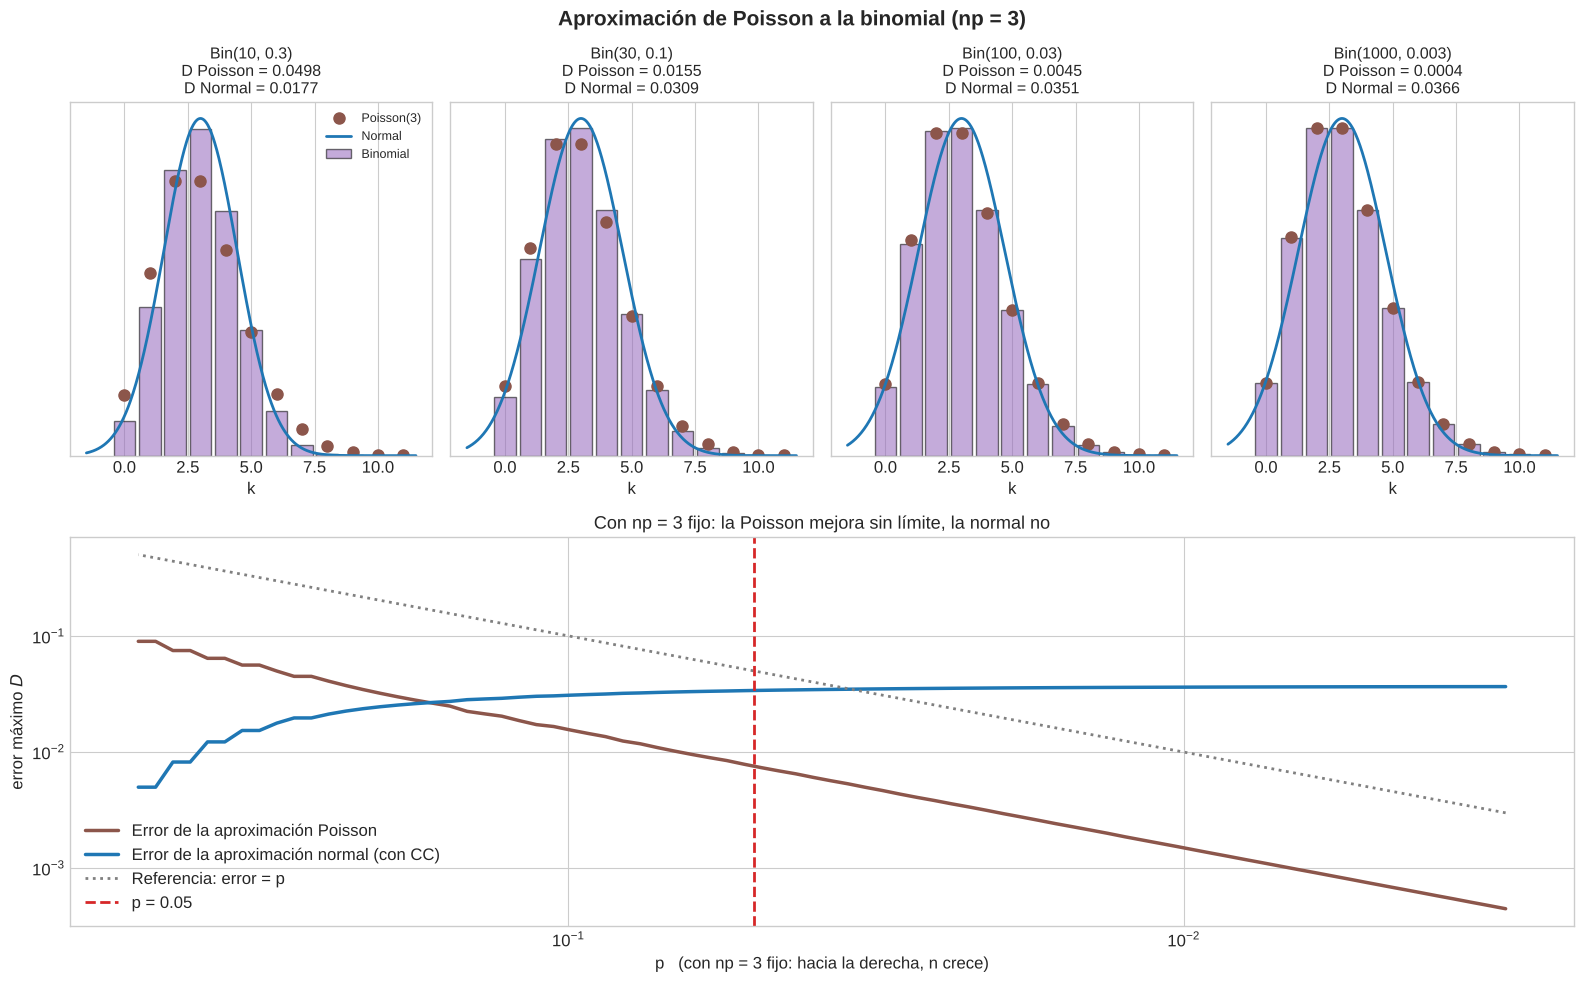

In [15]:
lam = 3
casos = [(10, 0.3), (30, 0.1), (100, 0.03), (1000, 0.003)]
k = np.arange(0, 12)
x = np.linspace(-1.5, 11.5, 600)
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.1])
for i, (n, p) in enumerate(casos):
    ax = fig.add_subplot(gs[0, i])
    s = np.sqrt(n * p * (1 - p))
    ax.bar(k, stats.binom.pmf(k, n, p), color=COLORES['Binomial'], alpha=0.55, edgecolor='black', width=0.85,
           label='Binomial')
    ax.plot(k, stats.poisson.pmf(k, lam), 'o', color=COLORES['Poisson'], ms=8, label='Poisson(3)')
    ax.plot(x, stats.norm.pdf(x, n * p, s), color=COLORES['Normal'], lw=2, label='Normal')
    ax.set_title(f'Bin({n}, {p})\nD Poisson = {D_binom_poisson(n, p):.4f}\nD Normal = {D_binom_normal(n, p):.4f}',
                 fontsize=11.5)
    ax.set_yticks([]); ax.set_xlabel('k')
    if i == 0: ax.legend(fontsize=9)
ax = fig.add_subplot(gs[1, :])
p_grilla = np.geomspace(0.003, 0.5, 80)
n_grilla = np.round(lam / p_grilla).astype(int)
ax.plot(p_grilla, [D_binom_poisson(n, lam / n) for n in n_grilla], color=COLORES['Poisson'], lw=2.5,
        label='Error de la aproximación Poisson')
ax.plot(p_grilla, [D_binom_normal(n, lam / n) for n in n_grilla], color=COLORES['Normal'], lw=2.5,
        label='Error de la aproximación normal (con CC)')
ax.plot(p_grilla, p_grilla, color='gray', ls=':', lw=2, label='Referencia: error = p')
ax.axvline(0.05, color=COLORES['Chebyshev'], ls='--', lw=2, label='p = 0.05')
ax.set_xscale('log'); ax.set_yscale('log'); ax.invert_xaxis()
ax.set_xlabel('p   (con np = 3 fijo: hacia la derecha, n crece)'); ax.set_ylabel('error máximo $D$')
ax.legend(loc='lower left'); ax.set_title('Con np = 3 fijo: la Poisson mejora sin límite, la normal no')
fig.suptitle('Aproximación de Poisson a la binomial (np = 3)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- Con $np$ fijo, el error de la Poisson **tiende a cero** a medida que $p \to 0$, y lo hace aproximadamente proporcional a $p$ (la línea punteada gris es de referencia: se puede demostrar que el error nunca la supera).
- El error de la normal, en cambio, **se estanca** en unos 3.5 puntos: con $np = 3$ la binomial límite es una Poisson(3), que es asimétrica, y ninguna cantidad de $n$ la vuelve normal.
- Lección: la normal necesita que **la media crezca** ($np \to \infty$); la Poisson necesita que **$p$ sea chico**. Son dos límites distintos.

### 2.7 El mapa completo: ¿cuál aproximación usar para cada $(n, p)$?
Calculamos el error máximo $D$ en una grilla de $n$ y $p$, para las dos aproximaciones de la binomial. Como $\text{Bin}(n, p)$ y $\text{Bin}(n, 1-p)$ son espejo una de la otra, alcanza con $p \le 0.5$.

- **Colores:** $\log_{10} D$. Verde = error chico, rojo = error grande.
- **Zona gris:** $np < 1$. Ahí la binomial vale casi siempre 0 y cualquier aproximación "acierta" trivialmente, así que no la mostramos.
- **Línea blanca:** donde el error vale exactamente 1 punto ($D = 0.01$).
- **Líneas rojas:** las reglas prácticas.

In [16]:
n_vals = np.unique(np.round(np.geomspace(5, 2000, 70)).astype(int))
p_vals = np.geomspace(0.002, 0.5, 70)
E_norm = np.array([[D_binom_normal(n, p) for n in n_vals] for p in p_vals])
E_pois = np.array([[D_binom_poisson(n, p) for n in n_vals] for p in p_vals])
print('Grilla calculada:', E_norm.shape)

Grilla calculada: (70, 67)


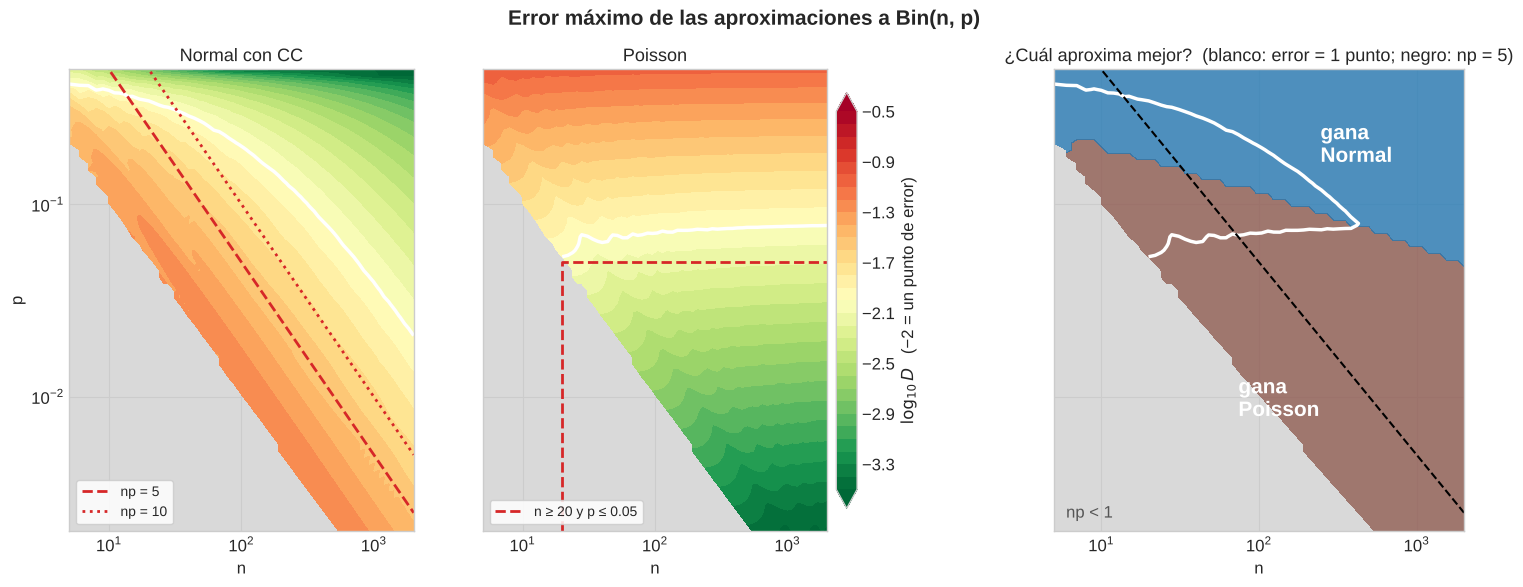

In [17]:
NN, PP = np.meshgrid(n_vals, p_vals)
trivial = NN * PP < 1                      # np < 1: la variable es casi siempre 0
niveles = np.linspace(-3.5, -0.5, 31)
fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, E, titulo in [(axs[0], E_norm, 'Normal con CC'), (axs[1], E_pois, 'Poisson')]:
    Z = np.where(trivial, np.nan, np.log10(np.clip(E, 10**-3.5, None)))
    ax.set_facecolor('#d9d9d9')
    cf = ax.contourf(NN, PP, Z, levels=niveles, cmap='RdYlGn_r', extend='both')
    ax.contour(NN, PP, np.where(trivial, np.nan, E), levels=[0.01], colors='white', linewidths=2.5)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('n'); ax.set_title(titulo)
# reglas prácticas
axs[0].plot(n_vals, 5 / n_vals, color=COLORES['Chebyshev'], ls='--', lw=2, label='np = 5')
axs[0].plot(n_vals, 10 / n_vals, color=COLORES['Chebyshev'], ls=':', lw=2, label='np = 10')
axs[1].plot([20, 20, 2000], [0.002, 0.05, 0.05], color=COLORES['Chebyshev'], ls='--', lw=2,
            label='n ≥ 20 y p ≤ 0.05')
for ax in axs[:2]:
    ax.set_ylim(p_vals[0], p_vals[-1]); ax.set_xlim(n_vals[0], n_vals[-1])
    ax.legend(loc='lower left', fontsize=10, facecolor='white', framealpha=0.85, frameon=True)
axs[0].set_ylabel('p')
cbar = fig.colorbar(cf, ax=axs[:2], pad=0.01, shrink=0.9)
cbar.set_label('$\\log_{10} D$   (−2 = un punto de error)')
# tercer panel: cuál gana
gana = np.where(trivial, np.nan, np.where(E_pois < E_norm, 0, 1))
axs[2].set_facecolor('#d9d9d9')
axs[2].contourf(NN, PP, gana, levels=[-0.5, 0.5, 1.5], colors=[COLORES['Poisson'], COLORES['Normal']], alpha=0.75)
axs[2].contour(NN, PP, np.where(trivial, np.nan, np.minimum(E_norm, E_pois)), levels=[0.01], colors='white', linewidths=2.5)
axs[2].text(0.03, 0.03, 'np < 1', transform=axs[2].transAxes, fontsize=12, color='#555555')
axs[2].text(0.45, 0.25, 'gana\nPoisson', transform=axs[2].transAxes, fontsize=15, color='white', fontweight='bold')
axs[2].text(0.65, 0.8, 'gana\nNormal', transform=axs[2].transAxes, fontsize=15, color='white', fontweight='bold')
axs[2].plot(n_vals, 5 / n_vals, color='black', ls='--', lw=1.5)
axs[2].set_xscale('log'); axs[2].set_yscale('log'); axs[2].set_xlabel('n')
axs[2].set_ylim(p_vals[0], p_vals[-1]); axs[2].set_xlim(n_vals[0], n_vals[-1])
axs[2].set_title('¿Cuál aproxima mejor?  (blanco: error = 1 punto; negro: np = 5)')
fig.suptitle('Error máximo de las aproximaciones a Bin(n, p)', fontsize=15, fontweight='bold')
plt.show()

#### 🔎 Lectura del mapa
- **Normal:** el error baja hacia la esquina de **$n$ grande y $p$ cerca de 0.5** (arriba a la derecha). Las curvas de nivel son casi paralelas a $np = \text{cte}$: por eso la regla se escribe en términos de $np$. Pero la línea blanca ($D = 0.01$) queda **bastante a la derecha** de $np = 5$ y de $np = 10$.
- **Poisson:** el error depende casi solo de $p$ (franjas horizontales), y es chico abajo, para $p$ pequeño, **sin importar $n$**.
- **Panel derecho:** la Poisson gana en toda la parte de abajo. La frontera **baja a medida que crece $n$**: con $n = 10$ la Poisson gana hasta $p \approx 0.15$, pero con $n$ del orden de 1000 solo hasta $p \approx 0.05$. Al crecer $n$, la normal mejora (porque $np$ crece) y la Poisson no (su error depende de $p$).
- Entre las dos líneas blancas del panel derecho queda una franja ($p$ entre 0.05 y 0.3, $n$ moderado) donde **ninguna** de las dos baja de 1 punto: ahí conviene calcular la binomial exacta.

### 2.8 🎛️ Explorá vos: calculá $P(a \le X \le b)$ de tres maneras
Elegí $n$, $p$ y el intervalo $[a, b]$. Se muestran:
- **Izquierda:** las barras de la binomial en $[a, b]$, el área de la normal entre $a - 0.5$ y $b + 0.5$, y los puntos de la Poisson.
- **Derecha:** el error $|F_{\text{exacta}}(k) - F_{\text{aprox}}(k)|$ para cada $k$; el máximo de cada curva es el $D$ de antes.

**Para probar:**
- $n = 20$, $p = 0.5$ contra $n = 20$, $p = 0.05$: ¿cuál conviene en cada caso?
- Un intervalo en la cola, por ejemplo $[0, 2]$ con $p = 0.85$.
- Apagá la corrección por continuidad y fijate cuánto empeora.

In [18]:
def lab_aproximaciones(n, p, intervalo, cc):
    a, b = intervalo
    a, b = min(a, n), min(b, n)
    mu, s, lam = n * p, np.sqrt(n * p * (1 - p)), n * p
    exacta = stats.binom.cdf(b, n, p) - stats.binom.cdf(a - 1, n, p)
    delta = 0.5 if cc else 0.0
    normal = stats.norm.cdf(b + delta, mu, s) - stats.norm.cdf(a - delta, mu, s)
    poisson = stats.poisson.cdf(b, lam) - stats.poisson.cdf(a - 1, lam)
    k = np.arange(max(0, int(mu - 5 * s) - 2), min(n, int(mu + 5 * s) + 3) + 1)
    k = np.union1d(k, np.arange(a, b + 1))
    dentro = (k >= a) & (k <= b)
    x = np.linspace(k[0] - 1, k[-1] + 1, 1500)
    fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
    axs[0].bar(k[~dentro], stats.binom.pmf(k[~dentro], n, p), color=COLORES['Binomial'], alpha=0.25,
               edgecolor='black', width=0.9)
    axs[0].bar(k[dentro], stats.binom.pmf(k[dentro], n, p), color=COLORES['Binomial'], alpha=0.8,
               edgecolor='black', width=0.9, label=f'Binomial exacta: {exacta:.4f}')
    axs[0].plot(x, stats.norm.pdf(x, mu, s), color=COLORES['Normal'], lw=2.5)
    axs[0].fill_between(x, stats.norm.pdf(x, mu, s), where=(x >= a - delta) & (x <= b + delta),
                        color=COLORES['Normal'], alpha=0.3,
                        label=f'Normal {"con" if cc else "sin"} CC: {normal:.4f}  ({normal - exacta:+.4f})')
    axs[0].plot(k, stats.poisson.pmf(k, lam), 'o', color=COLORES['Poisson'], ms=6,
                label=f'Poisson({lam:.3g}): {poisson:.4f}  ({poisson - exacta:+.4f})')
    axs[0].set_xlabel('k'); axs[0].set_yticks([]); axs[0].legend(loc='upper right', fontsize=10)
    regla_n = 'sí' if min(n * p, n * (1 - p)) >= 5 else 'no'
    regla_p = 'sí' if (n >= 20 and p <= 0.05) else 'no'
    axs[0].set_title(f'Bin({n}, {p:.3f}):  P({a} ≤ X ≤ {b})      ¿regla normal? {regla_n}   ¿regla Poisson? {regla_p}')
    kk = np.arange(0, n + 1)
    Fb = stats.binom.cdf(kk, n, p)
    err_n = np.abs(Fb - F_normal(kk, mu, s, cc))
    err_p = np.abs(Fb - stats.poisson.cdf(kk, lam))
    axs[1].plot(kk, err_n, '-o', color=COLORES['Normal'], ms=3, label=f'Normal: máx = {err_n.max():.4f}')
    axs[1].plot(kk, err_p, '-o', color=COLORES['Poisson'], ms=3, label=f'Poisson: máx = {err_p.max():.4f}')
    axs[1].axhline(0.01, color='gray', ls='-.', lw=1.2, label='1 punto')
    axs[1].set_xlim(k[0], k[-1]); axs[1].set_xlabel('k'); axs[1].set_ylabel('$|F_{exacta}(k) - F_{aprox}(k)|$')
    axs[1].legend(loc='upper right'); axs[1].set_title('Error en la acumulada, punto a punto')
    plt.tight_layout()
    plt.show()

w_n  = widgets.IntSlider(value=30, min=2, max=500, step=1, description='n', continuous_update=False)
w_p  = widgets.FloatSlider(value=0.1, min=0.001, max=0.999, step=0.001, readout_format='.3f',
                           description='p', continuous_update=False)
w_ab = widgets.IntRangeSlider(value=[2, 5], min=0, max=30, step=1, description='[a, b]', continuous_update=False)
w_cc = widgets.Checkbox(value=True, description='Corrección por continuidad')

def ajustar_rango(cambio):
    w_ab.max = cambio['new']
w_n.observe(ajustar_rango, names='value')

salida = widgets.interactive_output(lab_aproximaciones, dict(n=w_n, p=w_p, intervalo=w_ab, cc=w_cc))
display(widgets.VBox([widgets.HBox([w_n, w_p]), widgets.HBox([w_ab, w_cc]), salida]))

#### 🎛️ Y la Poisson contra la normal
Elegí $\lambda$ y un intervalo. Probá $\lambda = 50$ con $[61, 120]$: es el ejemplo del *call center* de la Clase 18.

In [19]:
def lab_poisson_normal(lam, intervalo, cc):
    a, b = intervalo
    s = np.sqrt(lam)
    exacta = stats.poisson.cdf(b, lam) - stats.poisson.cdf(a - 1, lam)
    delta = 0.5 if cc else 0.0
    normal = stats.norm.cdf(b + delta, lam, s) - stats.norm.cdf(a - delta, lam, s)
    k = np.arange(max(0, int(lam - 5 * s) - 2), int(lam + 5 * s) + 3)
    dentro = (k >= a) & (k <= b)
    x = np.linspace(k[0] - 1, k[-1] + 1, 1500)
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(k[~dentro], stats.poisson.pmf(k[~dentro], lam), color=COLORES['Poisson'], alpha=0.25,
           edgecolor='black', width=0.9)
    ax.bar(k[dentro], stats.poisson.pmf(k[dentro], lam), color=COLORES['Poisson'], alpha=0.8,
           edgecolor='black', width=0.9, label=f'Poisson exacta: {exacta:.4f}')
    ax.plot(x, stats.norm.pdf(x, lam, s), color=COLORES['Normal'], lw=2.5)
    ax.fill_between(x, stats.norm.pdf(x, lam, s), where=(x >= a - delta) & (x <= b + delta),
                    color=COLORES['Normal'], alpha=0.3,
                    label=f'Normal {"con" if cc else "sin"} CC: {normal:.4f}  (error rel. {(normal - exacta) / exacta:+.1%})')
    ax.set_xlim(k[0] - 1, k[-1] + 1)
    ax.set_xlabel('k'); ax.set_yticks([]); ax.legend(loc='upper right', fontsize=11)
    ax.set_title(f'Pois({lam:g}):  P({a} ≤ X ≤ {b})      D = {D_poisson_normal(lam, cc):.4f}'
                 f'      ¿regla λ ≥ 10? {"sí" if lam >= 10 else "no"}')
    plt.tight_layout()
    plt.show()

w_lam = widgets.FloatSlider(value=50, min=0.5, max=120, step=0.5, description='λ', continuous_update=False)
w_ab2 = widgets.IntRangeSlider(value=[61, 120], min=0, max=200, step=1, description='[a, b]',
                               continuous_update=False)
w_cc2 = widgets.Checkbox(value=True, description='Corrección por continuidad')
salida2 = widgets.interactive_output(lab_poisson_normal, dict(lam=w_lam, intervalo=w_ab2, cc=w_cc2))
display(widgets.VBox([widgets.HBox([w_lam, w_ab2, w_cc2]), salida2]))

### 2.9 Para cerrar la Parte 2
- La **corrección por continuidad** reduce el error de la aproximación normal a menos de la mitad. Siempre conviene usarla.
- La regla $np \ge 5$ asegura errores de **unos pocos puntos**, no de décimas. El error decrece como $1/\sqrt{np}$ y es peor cuanto más lejos de $0.5$ está $p$.
- Las reglas miran el **centro** de la distribución. En las **colas** el error relativo puede ser grande aunque la regla se cumpla con holgura.
- Con $p$ chico, la **Poisson** es mejor que la normal, y su error es del orden de $p$, independiente de $n$.
- Normal y Poisson son **dos límites distintos** de la binomial: la normal cuando $np \to \infty$, la Poisson cuando $p \to 0$ con $np$ fijo.

**Preguntas para pensar**
1. Si $X \sim \text{Bin}(400, 0.01)$, ¿qué aproximación usarías para $P(X \le 2)$? Mirá el mapa de 2.7 antes de calcular.
2. ¿Por qué la aproximación normal a la Poisson subestima $P(X > \lambda + 1.5\sqrt\lambda)$ en lugar de sobreestimarla?
3. En el panel derecho del mapa, ¿por qué la frontera entre las dos aproximaciones baja cuando $n$ crece?

---
# 🟢 PARTE 3: ¿Alcanza con $n \ge 30$?

### 3.1 Qué dice la regla y qué dice el teorema
El TCL dice que si $X_1, \dots, X_n$ son i.i.d. con media $\mu$ y varianza $\sigma^2 < \infty$, entonces
$$
Z_n = \frac{\overline X_n - \mu}{\sigma / \sqrt n} \;\xrightarrow{\ d\ }\; N(0, 1).
$$
Es un resultado **en el límite**: no dice nada sobre cuán grande tiene que ser $n$. La regla "$n \ge 30$" es una convención práctica que en la Clase 18 aparece con una advertencia: *depende de cuán lejos de la normal sea la distribución original*.

En esta parte la ponemos a prueba con cinco distribuciones de partida:

| Distribución | Por qué está | Asimetría $\gamma$ |
|---|---|---|
| Uniforme $U(0,1)$ | Simétrica, sin colas | $0$ |
| Exponencial $\text{Exp}(1)$ | Asimétrica "moderada" | $2$ |
| Bernoulli$(0.05)$ | Discreta y muy asimétrica: eventos raros | $\approx 4.1$ |
| Lognormal $LN(0, 1)$ | Continua, muy asimétrica, cola larga | $\approx 6.2$ |
| Cauchy | **No tiene varianza**: el TCL no aplica | no existe |

La **asimetría** (o coeficiente de asimetría) es $\gamma = E\big[(X-\mu)^3\big] / \sigma^3$. Va a resultar la pieza clave.

#### 📏 Tres formas de medir si $Z_n$ "ya es normal"
1. **Histograma contra densidad:** la mirada a ojo.
2. **Error en las colas:** comparar $P(Z_n > 2)$ y $P(Z_n < -2)$ con el valor normal $0.0228$. Es lo que importa al construir intervalos de confianza y tests (Unidades 6 y 7).
3. **Distancia de Kolmogorov:** $D_n = \sup_z \big|P(Z_n \le z) - \Phi(z)\big|$, el peor error posible sobre cualquier probabilidad del tipo $P(Z_n \le z)$. Es la misma idea que el $D$ de la Parte 2.

In [20]:
# Distribuciones de partida y cálculo de Z_n (exacto cuando se puede, simulado si no)
COLORES.update({'Lognormal': '#17becf', 'Bernoulli': '#bcbd22', 'Cauchy': '#6a5acd'})
P_BER = 0.05
DIST3 = {
    'Uniforme':    stats.uniform(),
    'Exponencial': stats.expon(),
    'Bernoulli':   stats.bernoulli(P_BER),
    'Lognormal':   stats.lognorm(s=1),
}
MU  = {k: d.mean() for k, d in DIST3.items()}
SIG = {k: d.std() for k, d in DIST3.items()}
GAM = {k: float(d.stats(moments='s')) for k, d in DIST3.items()}

N_GRID = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 300, 500, 750, 1000])
REPS = 100_000                         # repeticiones para las distribuciones simuladas
rng = np.random.default_rng(2026)

def simular_Z(dist, n, reps=REPS, bloque=10_000):
    # Z_n simulado: (promedio de n valores - mu) / (sigma / sqrt(n)), por bloques para no llenar la memoria
    mu, s = dist.mean(), dist.std()
    Z = np.empty(reps)
    for i in range(0, reps, bloque):
        m = min(bloque, reps - i)
        Z[i:i + m] = (dist.rvs(size=(m, n), random_state=rng).mean(axis=1) - mu) / (s / np.sqrt(n))
    return np.sort(Z)

# Simulamos solo Uniforme y Lognormal; Exponencial y Bernoulli tienen distribución exacta de la suma
Z_SIM = {k: {n: simular_Z(DIST3[k], n) for n in N_GRID} for k in ['Uniforme', 'Lognormal']}

# --- Acumulada de Z_n, exacta o empírica
def F_Zn(nombre, n, z):
    z = np.asarray(z, dtype=float)
    mu, s = MU[nombre], SIG[nombre]
    if nombre == 'Exponencial':          # suma de n Exp(1) ~ Gamma(n, 1)  =>  promedio ~ Gamma(n, escala 1/n)
        return stats.gamma.cdf(mu + z * s / np.sqrt(n), a=n, scale=1 / n)
    if nombre == 'Bernoulli':            # suma de n Bernoulli(p) ~ Bin(n, p)
        return stats.binom.cdf(np.floor(n * P_BER + z * s * np.sqrt(n) + 1e-9), n, P_BER)
    Z = Z_SIM[nombre][n]
    return np.searchsorted(Z, z, side='right') / len(Z)

def colas(nombre, n):
    # devuelve (P(Z_n > 2), P(Z_n < -2))
    if nombre == 'Bernoulli':
        s, m = SIG[nombre] * np.sqrt(n), n * P_BER
        return (stats.binom.sf(np.floor(m + 2 * s + 1e-9), n, P_BER),
                stats.binom.cdf(np.ceil(m - 2 * s - 1e-9) - 1, n, P_BER))
    if nombre == 'Exponencial':
        return 1 - F_Zn(nombre, n, 2), F_Zn(nombre, n, -2)
    Z = Z_SIM[nombre][n]
    return np.mean(Z > 2), np.mean(Z < -2)

def kolmogorov(nombre, n):
    if nombre == 'Bernoulli':            # se evalúa en los saltos, a izquierda y derecha
        k = np.arange(0, n + 1)
        z = (k - n * P_BER) / (SIG[nombre] * np.sqrt(n))
        F = stats.binom.cdf(k, n, P_BER)
        F_izq = np.concatenate([[0.0], F[:-1]])
        return max(np.max(np.abs(F - stats.norm.cdf(z))), np.max(np.abs(F_izq - stats.norm.cdf(z))))
    if nombre == 'Exponencial':
        z = np.linspace(-np.sqrt(n), 12, 40001)
        return np.max(np.abs(F_Zn(nombre, n, z) - stats.norm.cdf(z)))
    return stats.kstest(Z_SIM[nombre][n], 'norm').statistic

TABLA_COLAS = {k: np.array([colas(k, n) for n in N_GRID]) for k in DIST3}
TABLA_D     = {k: np.array([kolmogorov(k, n) for n in N_GRID]) for k in DIST3}
print('Asimetrías:', {k: round(v, 2) for k, v in GAM.items()})
print('Listo: colas y distancias de Kolmogorov calculadas para n =', [int(n) for n in N_GRID])

Asimetrías: {'Uniforme': 0.0, 'Exponencial': 2.0, 'Bernoulli': 4.13, 'Lognormal': 6.18}
Listo: colas y distancias de Kolmogorov calculadas para n = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 50, 75, 100, 150, 200, 300, 500, 750, 1000]


### 3.2 La mirada a ojo: histogramas de $Z_n$
Cada fila es una distribución de partida; cada columna, un tamaño de muestra. En negro, la densidad $N(0,1)$. En el título, la distancia de Kolmogorov $D_n$.

- **Uniforme y lognormal:** histograma de $100\,000$ valores simulados de $Z_n$.
- **Exponencial y Bernoulli:** distribución **exacta** de $Z_n$ (la suma de exponenciales es una gamma; la de Bernoulli, una binomial).

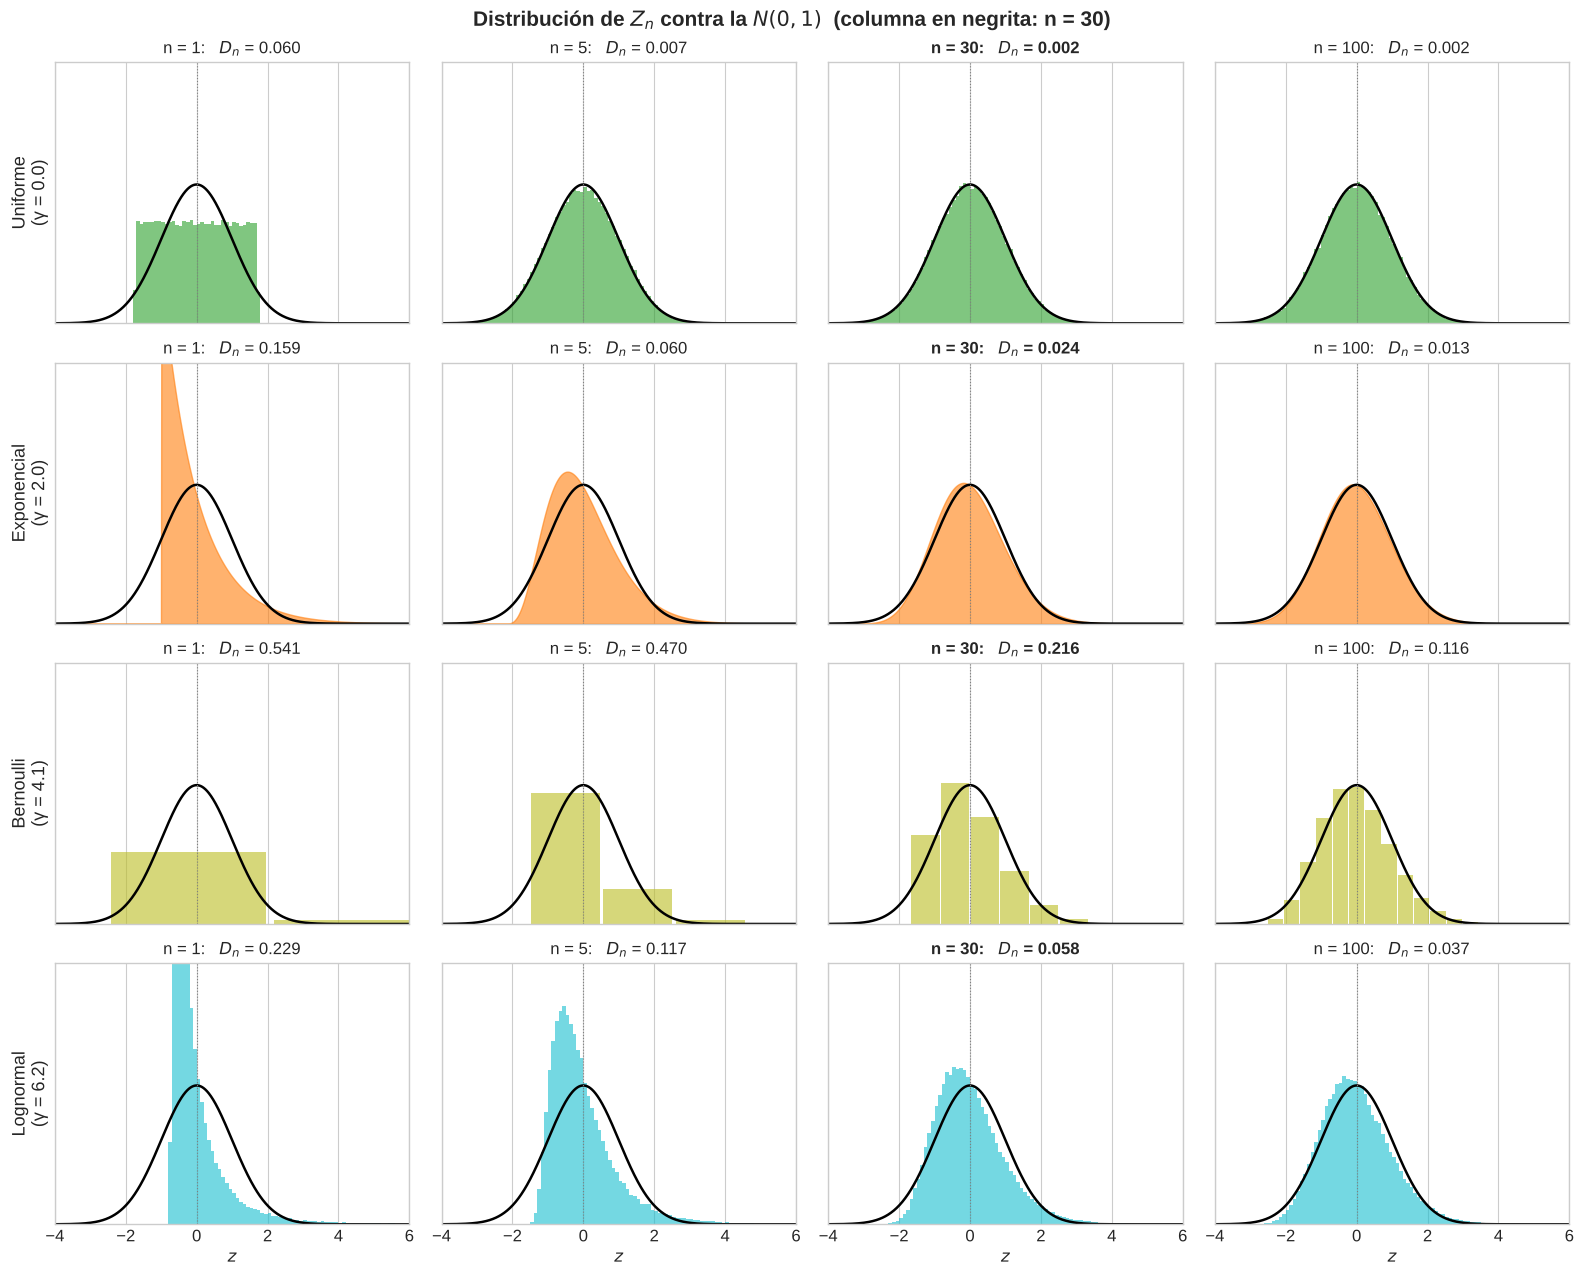

In [21]:
ns_hist = [1, 5, 30, 100]
filas = ['Uniforme', 'Exponencial', 'Bernoulli', 'Lognormal']
z = np.linspace(-4, 6, 1000)
bordes = np.linspace(-4, 6, 101)
fig, axs = plt.subplots(4, 4, figsize=(16, 13), sharex=True)
for i, nombre in enumerate(filas):
    col = COLORES[nombre]
    for j, n in enumerate(ns_hist):
        ax = axs[i, j]
        if nombre in Z_SIM:
            cuentas, _ = np.histogram(Z_SIM[nombre][n], bins=bordes)
            ax.bar(bordes[:-1], cuentas / (REPS * np.diff(bordes)), width=np.diff(bordes), align='edge',
                   color=col, alpha=0.6)
        elif nombre == 'Exponencial':
            dens = stats.gamma.pdf(1 + z / np.sqrt(n), a=n, scale=1 / n) / np.sqrt(n)
            ax.fill_between(z, dens, color=col, alpha=0.6)
        else:
            k = np.arange(0, n + 1)
            zk = (k - n * P_BER) / (SIG[nombre] * np.sqrt(n))
            paso = 1 / (SIG[nombre] * np.sqrt(n))
            ax.bar(zk, stats.binom.pmf(k, n, P_BER) / paso, width=0.95 * paso, color=col, alpha=0.6)
        ax.plot(z, stats.norm.pdf(z), color='black', lw=1.8)
        ax.axvline(0, color='gray', lw=0.8, ls=':')
        ax.set_xlim(-4, 6); ax.set_ylim(0, 0.75); ax.set_yticks([])
        ax.set_title(f'n = {n}:   $D_n$ = {TABLA_D[nombre][list(N_GRID).index(n)]:.3f}', fontsize=12,
                     fontweight='bold' if n == 30 else 'normal')
        if j == 0:
            ax.set_ylabel(f'{nombre}\n(γ = {GAM[nombre]:.1f})', fontsize=13)
for ax in axs[-1]:
    ax.set_xlabel('$z$')
fig.suptitle('Distribución de $Z_n$ contra la $N(0,1)$  (columna en negrita: n = 30)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Fijate que...
- La **uniforme** ya parece normal con $n = 5$. Para ella, $30$ es mucho más de lo necesario.
- La **exponencial** con $n = 30$ se ve bastante bien, aunque todavía se nota el corrimiento: el pico está un poco a la izquierda de 0 y la cola derecha es más larga.
- La **Bernoulli(0.05)** con $n = 30$ todavía está "pegada a la pared": $n p = 1.5$, la suma vale casi siempre 0, 1 o 2. Es exactamente el caso $np < 5$ de la Parte 2.
- La **lognormal** con $n = 30$ sigue claramente torcida, y con $n = 100$ todavía se nota la asimetría.

### 3.3 Las colas: $P(Z_n > 2)$ y $P(Z_n < -2)$
Si $Z_n$ fuera normal, las dos valdrían $1 - \Phi(2) \approx 0.0228$. Esta es la medida que más importa en la práctica: un intervalo de confianza de nivel 95% o un test con 5% de significación dependen justamente de que estas colas estén bien.

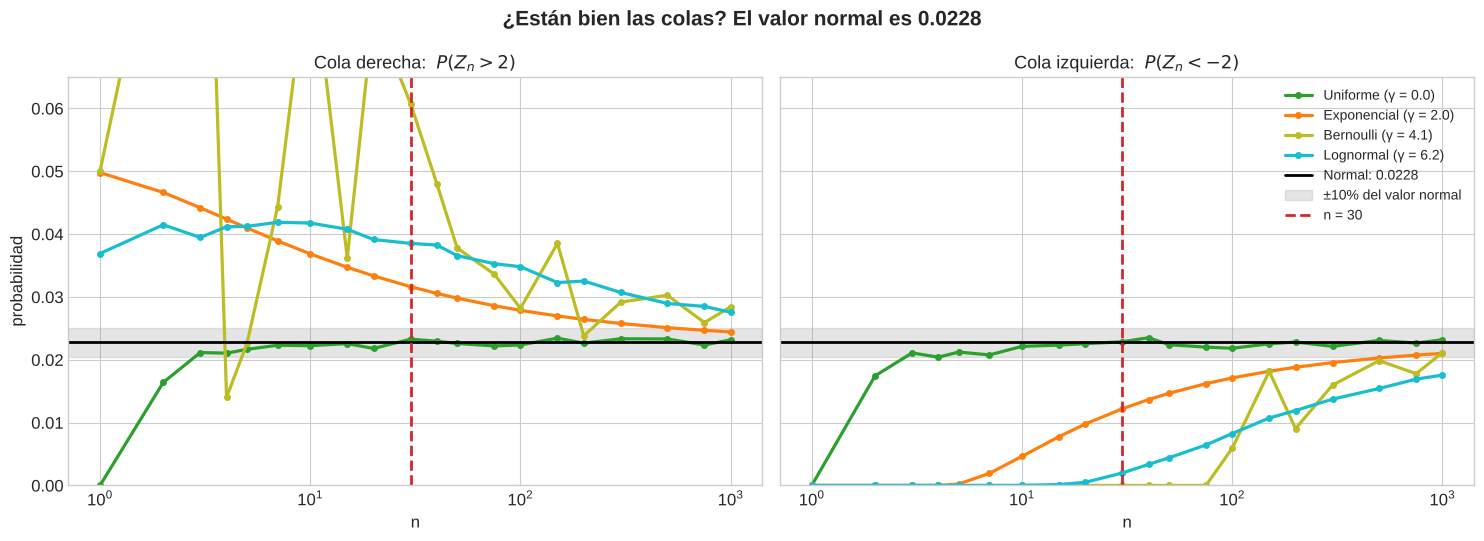

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for nombre in DIST3:
    T = TABLA_COLAS[nombre]
    estilo = dict(color=COLORES[nombre], lw=2.3, marker='o', ms=4, label=f'{nombre} (γ = {GAM[nombre]:.1f})')
    axs[0].plot(N_GRID, T[:, 0], **estilo)
    axs[1].plot(N_GRID, T[:, 1], **estilo)
p_normal = stats.norm.sf(2)
for ax, titulo in zip(axs, ['Cola derecha:  $P(Z_n > 2)$', 'Cola izquierda:  $P(Z_n < -2)$']):
    ax.axhline(p_normal, color='black', lw=2, label='Normal: 0.0228')
    ax.axhspan(0.9 * p_normal, 1.1 * p_normal, color='gray', alpha=0.2, label='±10% del valor normal')
    ax.axvline(30, color=COLORES['Chebyshev'], ls='--', lw=2, label='n = 30')
    ax.set_xscale('log'); ax.set_ylim(0, 0.065)
    ax.set_xlabel('n'); ax.set_title(titulo)
axs[0].set_ylabel('probabilidad')
axs[1].legend(loc='upper right', fontsize=10)
fig.suptitle('¿Están bien las colas? El valor normal es 0.0228', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- Las distribuciones **asimétricas a la derecha** tienen la cola derecha **más pesada** y la izquierda **más liviana** que la normal: la normal subestima la primera y sobreestima la segunda.
- En $n = 30$, la exponencial tiene $P(Z_n > 2) \approx 0.032$ y $P(Z_n < -2) \approx 0.012$: errores de **+39% y −46%**, uno para cada lado. Recién con $n$ del orden de 750 entra en la franja de ±10%.
- La lognormal y la Bernoulli$(0.05)$ están lejísimos de la franja en $n = 30$, y ni siquiera con $n = 1000$ terminan de entrar.
- La Bernoulli zigzaguea: es discreta, y $P(Z_n > 2)$ salta cada vez que el umbral cruza un entero.
- La uniforme entra en la franja enseguida. Ojo: con $n$ muy chico sus colas son **más livianas** que las de la normal, porque la uniforme no tiene colas.

### 3.4 La distancia de Kolmogorov y la cota de Berry–Esseen
Hay un teorema que dice **cuán rápido** converge el TCL. La **desigualdad de Berry–Esseen** afirma que, si $\rho = E|X - \mu|^3 < \infty$,
$$
D_n = \sup_z \big|P(Z_n \le z) - \Phi(z)\big| \;\le\; \frac{C\, \rho}{\sigma^3\, \sqrt n}, \qquad C \le 0.4748.
$$
Dos lecturas:
- El error baja como $1/\sqrt n$: para dividirlo por 2 hay que **cuadruplicar** $n$.
- La constante $\rho/\sigma^3$ es parecida a la asimetría $|\gamma|$ (de hecho $\rho/\sigma^3 \ge |\gamma|$): **cuanto más asimétrica la distribución, más grande hay que tomar $n$.**

En el gráfico, las líneas continuas son el $D_n$ real y las punteadas, la cota de Berry–Esseen.

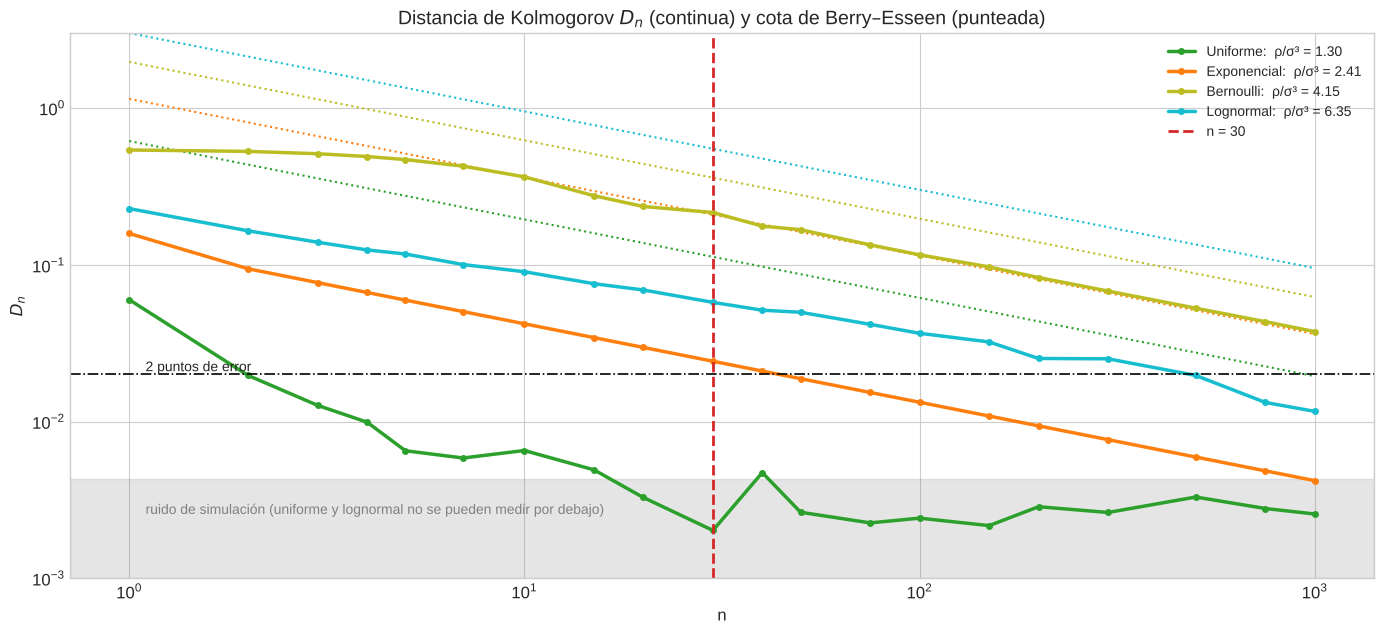

In [23]:
from scipy.integrate import quad
C_BE = 0.4748
def rho3(nombre):
    d, mu = DIST3[nombre], MU[nombre]
    if nombre == 'Bernoulli':
        p, q = P_BER, 1 - P_BER
        return p * q * (p**2 + q**2)
    a, b = d.support()
    g = lambda x: abs(x - mu)**3 * d.pdf(x)
    return quad(g, a, mu, limit=500)[0] + quad(g, mu, b, limit=500)[0]
RHO = {k: rho3(k) for k in DIST3}

ns = np.geomspace(1, 1000, 200)
piso_mc = 1.36 / np.sqrt(REPS)          # tamaño típico del ruido de simulación en D_n
fig, ax = plt.subplots(figsize=(14, 6.5))
for nombre in DIST3:
    col = COLORES[nombre]
    ax.plot(N_GRID, TABLA_D[nombre], color=col, lw=2.5, marker='o', ms=4,
            label=f'{nombre}:  ρ/σ³ = {RHO[nombre] / SIG[nombre]**3:.2f}')
    ax.plot(ns, C_BE * RHO[nombre] / SIG[nombre]**3 / np.sqrt(ns), color=col, lw=1.5, ls=':')
ax.axhspan(1e-4, piso_mc, color='gray', alpha=0.2)
ax.text(1.1, piso_mc * 0.6, 'ruido de simulación (uniforme y lognormal no se pueden medir por debajo)',
        color='gray', fontsize=10)
ax.axhline(0.02, color='black', ls='-.', lw=1.2)
ax.text(1.1, 0.021, '2 puntos de error', fontsize=10)
ax.axvline(30, color=COLORES['Chebyshev'], ls='--', lw=2, label='n = 30')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-3, 3)
ax.set_xlabel('n'); ax.set_ylabel('$D_n$')
ax.legend(loc='upper right', fontsize=10)
ax.set_title('Distancia de Kolmogorov $D_n$ (continua) y cota de Berry–Esseen (punteada)', fontsize=14)
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- **Todas** las curvas reales están por debajo de su cota punteada del mismo color. Las asimétricas, para $n$ grande, caen con pendiente $-1/2$ en escala log-log: el ritmo $1/\sqrt n$ se ve a simple vista.
- La cota de Berry–Esseen es **conservadora** (igual que Chebyshev en la Parte 1), pero ordena bien a las continuas: la lognormal, con $\rho/\sigma^3$ más grande, tarda más que la exponencial.
- La uniforme converge **más rápido** que $1/\sqrt n$, porque es simétrica: el término de asimetría, que es el que manda el error, vale cero.
- La Bernoulli queda **peor que la lognormal** aunque es menos asimétrica: además es **discreta**. Sin corrección por continuidad, $D_n$ no puede ser más chico que la mitad del salto más grande de la acumulada. Es el mismo fenómeno de la Parte 2; de hecho, para $n$ grande su curva va pegada a su propia cota.

### 3.5 Entonces, ¿qué $n$ hace falta?
Para cada distribución buscamos el menor $n$ de la grilla **a partir del cual** el criterio se cumple siempre:
- $D_n \le 0.02$ (a lo sumo 2 puntos de error en cualquier probabilidad),
- cola derecha y cola izquierda a menos del 10% de $0.0228$.

La última columna es el $n$ que **garantiza** $D_n \le 0.02$ según Berry–Esseen: $n \ge \left(\dfrac{C\rho}{0.02\,\sigma^3}\right)^2$.

In [24]:
def primer_n_estable(cumple):
    # menor n de la grilla tal que el criterio se cumple para ese n y todos los mayores
    for i in range(len(N_GRID)):
        if np.all(cumple[i:]):
            return str(N_GRID[i])
    return f'> {N_GRID[-1]}'

filas = []
for nombre in DIST3:
    T, Dn = TABLA_COLAS[nombre], TABLA_D[nombre]
    p_n = stats.norm.sf(2)
    filas.append({
        'Distribución': nombre,
        'Asimetría γ': GAM[nombre],
        'D_n ≤ 0.02': primer_n_estable(Dn <= 0.02),
        'Cola derecha ±10%': primer_n_estable(np.abs(T[:, 0] / p_n - 1) <= 0.10),
        'Cola izquierda ±10%': primer_n_estable(np.abs(T[:, 1] / p_n - 1) <= 0.10),
        'Garantía Berry–Esseen': f'{int(np.ceil((C_BE * RHO[nombre] / SIG[nombre]**3 / 0.02)**2)):,}'.replace(',', '.'),
    })
tabla_n = pd.DataFrame(filas).set_index('Distribución')
display(tabla_n.style.format({'Asimetría γ': '{:.2f}'})
        .set_caption('Menor n (de la grilla) desde el cual se cumple cada criterio'))

,Asimetría γ,D_n ≤ 0.02,Cola derecha ±10%,Cola izquierda ±10%,Garantía Berry–Esseen
Distribución,,,,,
Uniforme,0.00,2,3,5,952
Exponencial,2.00,50,750,750,3.286
Bernoulli,4.13,> 1000,> 1000,1000,9.718
Lognormal,6.18,500,> 1000,> 1000,22.726


#### 🔎 La moraleja de la tabla
- **No existe un $n$ universal.** El $n$ necesario va de menos de 10 (uniforme) a varios cientos o más (lognormal, Bernoulli con $p$ chico), y crece con la asimetría.
- Las **colas** piden mucho más $n$ que el "centro" de la distribución: para la exponencial, $D_n \le 0.02$ se logra con $n = 50$, pero las colas a ±10% recién con $n = 750$. Con $n = 30$ el histograma se ve normal y las colas se equivocan en un 40%.
- La garantía de Berry–Esseen es muy pesimista (miles), pero es una **garantía**: vale para cualquier distribución con esa asimetría.
- La regla $n \ge 30$ funciona razonablemente para distribuciones **simétricas o moderadamente asimétricas** ($|\gamma| \lesssim 1$). Una regla práctica usada en algunos textos es $n > 25\,\gamma^2$; con $\gamma = 2$ (exponencial) da $n > 100$, que alcanza para el centro pero no para las colas.

### 3.6 Cuando el TCL no aplica: la Cauchy
La Cauchy estándar tiene densidad $f(x) = \dfrac{1}{\pi(1 + x^2)}$. Sus colas son tan pesadas que **no tiene esperanza** (y menos varianza): la integral $\int |x| f(x)\,dx$ diverge.

Se puede probar con la función característica que **el promedio de $n$ Cauchy independientes es otra vez una Cauchy estándar**, para todo $n$. Promediar no sirve de nada: $\overline X_{1000}$ está tan disperso como una sola observación.

Como no hay $\sigma$, no se puede estandarizar: graficamos $\overline X_n$ directamente.

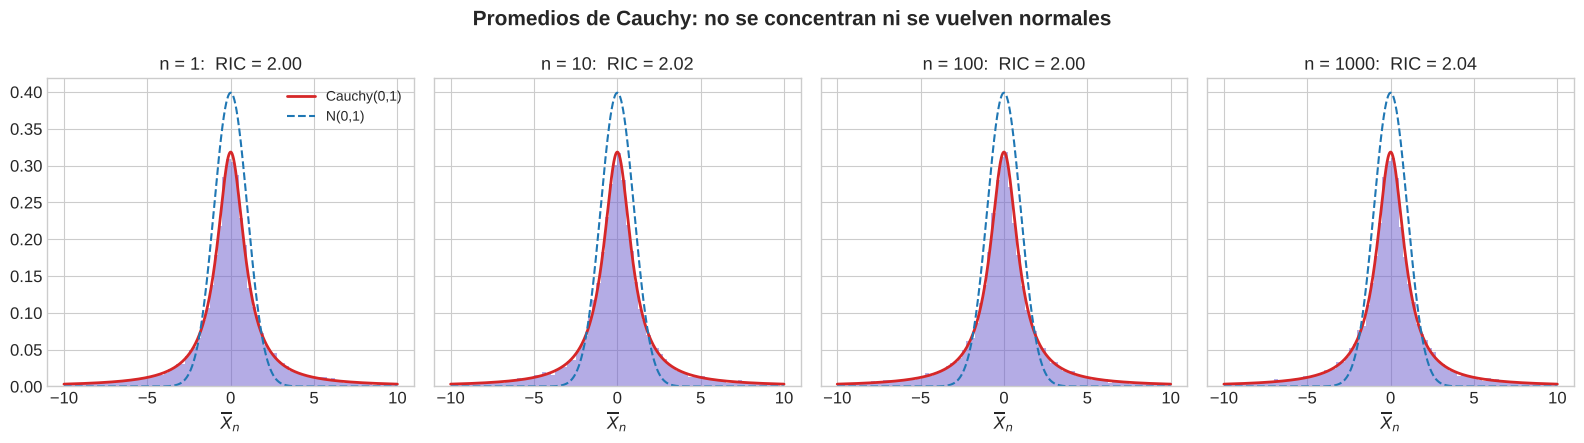

,Rango intercuartil de la media,P(|media| > 10)
n,,
1,2.005,0.065
10,2.018,0.062
100,1.996,0.060
1000,2.042,0.063


In [25]:
ns_cauchy = [1, 10, 100, 1000]
reps_c = 20_000
x = np.linspace(-10, 10, 1000)
bordes = np.linspace(-10, 10, 81)
fig, axs = plt.subplots(1, 4, figsize=(16, 4.5), sharey=True)
filas = []
for ax, n in zip(axs, ns_cauchy):
    medias = stats.cauchy.rvs(size=(reps_c, n), random_state=rng).mean(axis=1)
    cuentas, _ = np.histogram(medias, bins=bordes)
    ax.bar(bordes[:-1], cuentas / (reps_c * np.diff(bordes)), width=np.diff(bordes), align='edge',
           color=COLORES['Cauchy'], alpha=0.5)
    ax.plot(x, stats.cauchy.pdf(x), color=COLORES['Chebyshev'], lw=2, label='Cauchy(0,1)')
    ax.plot(x, stats.norm.pdf(x), color=COLORES['Normal'], lw=1.5, ls='--', label='N(0,1)')
    q1, q3 = np.percentile(medias, [25, 75])
    filas.append({'n': n, 'Rango intercuartil de la media': q3 - q1,
                  'P(|media| > 10)': np.mean(np.abs(medias) > 10)})
    ax.set_title(f'n = {n}:  RIC = {q3 - q1:.2f}')
    ax.set_xlabel(r'$\overline{X}_n$')
axs[0].legend(fontsize=10)
fig.suptitle('Promedios de Cauchy: no se concentran ni se vuelven normales', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()
display(pd.DataFrame(filas).set_index('n').style.format('{:.3f}')
        .set_caption('El rango intercuartil (RIC) teórico de la Cauchy(0,1) es 2, para todo n'))

#### 🔎 Lectura
- Los cuatro histogramas son **iguales** entre sí y coinciden con la densidad Cauchy (roja), no con la normal.
- El **rango intercuartil** se queda en 2 para todo $n$: el promedio no se concentra. Comparalo con una distribución con varianza, donde el rango intercuartil de $\overline X_n$ se achica como $1/\sqrt n$.
- La hipótesis $\sigma^2 < \infty$ del TCL (y de la ley débil) **no es un tecnicismo**. En la Parte 4 vamos a ver qué hacen las trayectorias del promedio de una Cauchy.

### 3.7 🎛️ Explorá vos
Elegí la distribución de partida, sus parámetros y $n$. Se simulan $20\,000$ promedios.
- **Izquierda:** histograma de $Z_n$ contra la $N(0,1)$. Para la Cauchy se grafica $\overline X_n$ sin estandarizar.
- **Derecha:** acumulada empírica de $Z_n$ contra $\Phi$, con la distancia de Kolmogorov $D_n$ marcada.

**Para probar:**
- Lognormal con $\sigma_{\log} = 0.25$ (casi simétrica) y con $\sigma_{\log} = 1.5$: con el mismo $n = 30$, ¿cuál está bien?
- Bernoulli con $p = 0.5$ y con $p = 0.01$, ambas con $n = 30$.
- Cauchy con $n = 1$ y con $n = 500$.

In [26]:
def dist_lab(familia, s_log, p_ber):
    return {'Uniforme': stats.uniform(), 'Exponencial': stats.expon(),
            'Lognormal': stats.lognorm(s=s_log), 'Bernoulli': stats.bernoulli(p_ber),
            'Cauchy': stats.cauchy()}[familia]

def lab_tcl(familia, n, s_log, p_ber):
    d = dist_lab(familia, s_log, p_ber)
    reps = 20_000
    medias = np.concatenate([d.rvs(size=(min(2000, reps - i), n), random_state=rng).mean(axis=1)
                             for i in range(0, reps, 2000)])
    col = COLORES[familia]
    fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
    if familia == 'Cauchy':
        Z, ref, nombre_ref, rango = medias, stats.cauchy, 'Cauchy(0,1)', (-10, 10)
    else:
        Z = (medias - d.mean()) / (d.std() / np.sqrt(n))
        ref, nombre_ref, rango = stats.norm, 'N(0,1)', (-4.5, 6)
    z = np.linspace(*rango, 1000)
    bordes = np.linspace(*rango, 91)
    cuentas, _ = np.histogram(Z, bins=bordes)
    axs[0].bar(bordes[:-1], cuentas / (reps * np.diff(bordes)), width=np.diff(bordes), align='edge',
               color=col, alpha=0.6, label=f'{reps:,} promedios simulados'.replace(',', '.'))
    axs[0].plot(z, ref.pdf(z), color='black', lw=2, label=nombre_ref)
    if familia == 'Cauchy':
        axs[0].plot(z, stats.norm.pdf(z), color=COLORES['Normal'], ls='--', lw=1.5, label='N(0,1)')
    axs[0].set_xlim(*rango); axs[0].set_yticks([]); axs[0].legend(loc='upper right')
    if familia == 'Cauchy':
        axs[0].set_title(f'Cauchy, n = {n}:  la media no se estandariza (no hay σ)')
    else:
        g = float(d.stats(moments='s'))
        cd, ci = np.mean(Z > 2), np.mean(Z < -2)
        axs[0].set_title(f'{familia}, n = {n}  (γ = {g:.2f}):   P(Z>2) = {cd:.4f}   P(Z<−2) = {ci:.4f}'
                         f'   [normal: 0.0228]', fontsize=12)
    Zs = np.sort(Z)
    F_emp = np.arange(1, reps + 1) / reps
    dif = np.abs(F_emp - ref.cdf(Zs))
    i = np.argmax(dif)
    axs[1].step(Zs, F_emp, where='post', color=col, lw=2, label='Acumulada empírica')
    axs[1].plot(z, ref.cdf(z), color='black', lw=1.8, label=nombre_ref)
    axs[1].vlines(Zs[i], F_emp[i], ref.cdf(Zs[i]), color=COLORES['Chebyshev'], lw=3, label=f'$D_n$ = {dif[i]:.4f}')
    axs[1].set_xlim(*rango); axs[1].legend(loc='lower right')
    axs[1].set_title('Acumulada: el segmento rojo es la máxima diferencia')
    plt.tight_layout()
    plt.show()

w_fam3 = widgets.Dropdown(options=['Uniforme', 'Exponencial', 'Lognormal', 'Bernoulli', 'Cauchy'],
                          value='Exponencial', description='Partida')
w_n3   = widgets.IntSlider(value=30, min=1, max=500, step=1, description='n', continuous_update=False)
w_slog = widgets.FloatSlider(value=1.0, min=0.1, max=2.0, step=0.05, description='σ_log', continuous_update=False)
w_pber = widgets.FloatSlider(value=0.05, min=0.01, max=0.5, step=0.01, description='p', continuous_update=False)

def mostrar_sliders3(*_):
    w_slog.layout.display = 'flex' if w_fam3.value == 'Lognormal' else 'none'
    w_pber.layout.display = 'flex' if w_fam3.value == 'Bernoulli' else 'none'
w_fam3.observe(mostrar_sliders3, names='value')
mostrar_sliders3()

salida3 = widgets.interactive_output(lab_tcl, dict(familia=w_fam3, n=w_n3, s_log=w_slog, p_ber=w_pber))
display(widgets.VBox([widgets.HBox([w_fam3, w_n3, w_slog, w_pber]), salida3]))

### 3.8 Para cerrar la Parte 3
- El TCL es un resultado **asintótico**: no dice qué $n$ alcanza. La regla $n \ge 30$ es una convención, no un teorema.
- La velocidad de convergencia la controla la **asimetría**: Berry–Esseen dice que el error es a lo sumo $C\rho/(\sigma^3\sqrt n)$.
- Distribuciones **simétricas** convergen muy rápido (uniforme: $n = 5$ alcanza). Distribuciones **muy asimétricas** necesitan cientos de observaciones.
- Las **colas** convergen más lento que el centro, y son justamente las que usamos en intervalos de confianza y tests.
- Sin varianza finita (**Cauchy**) no hay TCL: el promedio no se concentra ni se vuelve normal.

**Preguntas para pensar**
1. Los ingresos de una población suelen tener una distribución muy asimétrica a la derecha. Si querés estimar el ingreso medio con una muestra de 30 personas, ¿confiarías en un intervalo basado en la normal? ¿Hacia qué lado esperás que falle?
2. La Bernoulli$(0.05)$ con $n = 30$ falla, pero la Bernoulli$(0.5)$ con $n = 30$ anda bien. Conectalo con la regla $np \ge 5$ de la Parte 2.
3. ¿Por qué la uniforme converge más rápido que lo que predice Berry–Esseen?

---
# 🔵 PARTE 4: Ley débil de los grandes números — trayectorias de $\overline X_n$

### 4.1 Recordatorio
Si $X_1, X_2, \dots$ son i.i.d. con media $\mu$ y varianza $\sigma^2 < \infty$, la **ley débil de los grandes números (LGN)** dice que para todo $\varepsilon > 0$
$$
P\big(|\overline X_n - \mu| \ge \varepsilon\big) \;\xrightarrow[n\to\infty]{}\; 0.
$$
La demostración de la Clase 17 es Chebyshev aplicada a $\overline X_n$, que tiene media $\mu$ y varianza $\sigma^2/n$:
$$
P\big(|\overline X_n - \mu| \ge \varepsilon\big) \;\le\; \frac{\sigma^2}{n\,\varepsilon^2}.
$$

Una **trayectoria** es lo que ve alguien que va tirando el dado (o midiendo, o encuestando) una vez por vez y recalcula el promedio cada vez: la sucesión
$$
\overline X_1,\ \overline X_2,\ \overline X_3,\ \dots
$$
para **una** realización del experimento. En esta parte simulamos muchas trayectorias y miramos tres cosas:
1. cómo se van encerrando alrededor de $\mu$,
2. qué fracción se escapa de la banda $\mu \pm \varepsilon$ para cada $n$, comparada con Chebyshev y con el TCL,
3. qué pasa cuando no hay varianza (Cauchy).

In [27]:
# Trayectorias del promedio acumulado
def trayectorias(dist, n_max, m, semilla=1):
    # devuelve una matriz m x n_max: fila i = (Xbar_1, ..., Xbar_nmax) de la trayectoria i
    X = dist.rvs(size=(m, n_max), random_state=np.random.default_rng(semilla))
    return np.cumsum(X, axis=1) / np.arange(1, n_max + 1)

DIST4 = {
    'Moneda: Bernoulli(0.5)': (stats.bernoulli(0.5), COLORES['Binomial']),
    'Exponencial(1)':         (stats.expon(),        COLORES['Exponencial']),
    'Lognormal(0, 1)':        (stats.lognorm(s=1),   COLORES['Lognormal']),
    'Cauchy(0, 1)':           (stats.cauchy(),       COLORES['Cauchy']),
}
print('Listo.')

Listo.


### 4.2 Trayectorias y embudos
Para cada distribución, 30 trayectorias hasta $n = 5000$ (eje $n$ en escala logarítmica). Sobre ellas:
- **Línea negra:** la media $\mu$.
- **Embudo azul (TCL):** $\mu \pm 1.96\,\sigma/\sqrt n$. Para cada $n$, aproximadamente el 95% de las trayectorias debería estar adentro.
- **Embudo rojo (Chebyshev):** $\mu \pm \sigma/\sqrt{0.05\,n} \approx \mu \pm 4.47\,\sigma/\sqrt n$. Chebyshev **garantiza** que al menos el 95% esté adentro, para cualquier distribución.

En la Cauchy no hay $\sigma$: no se pueden dibujar embudos. Ponemos una línea en 0, su centro de simetría.

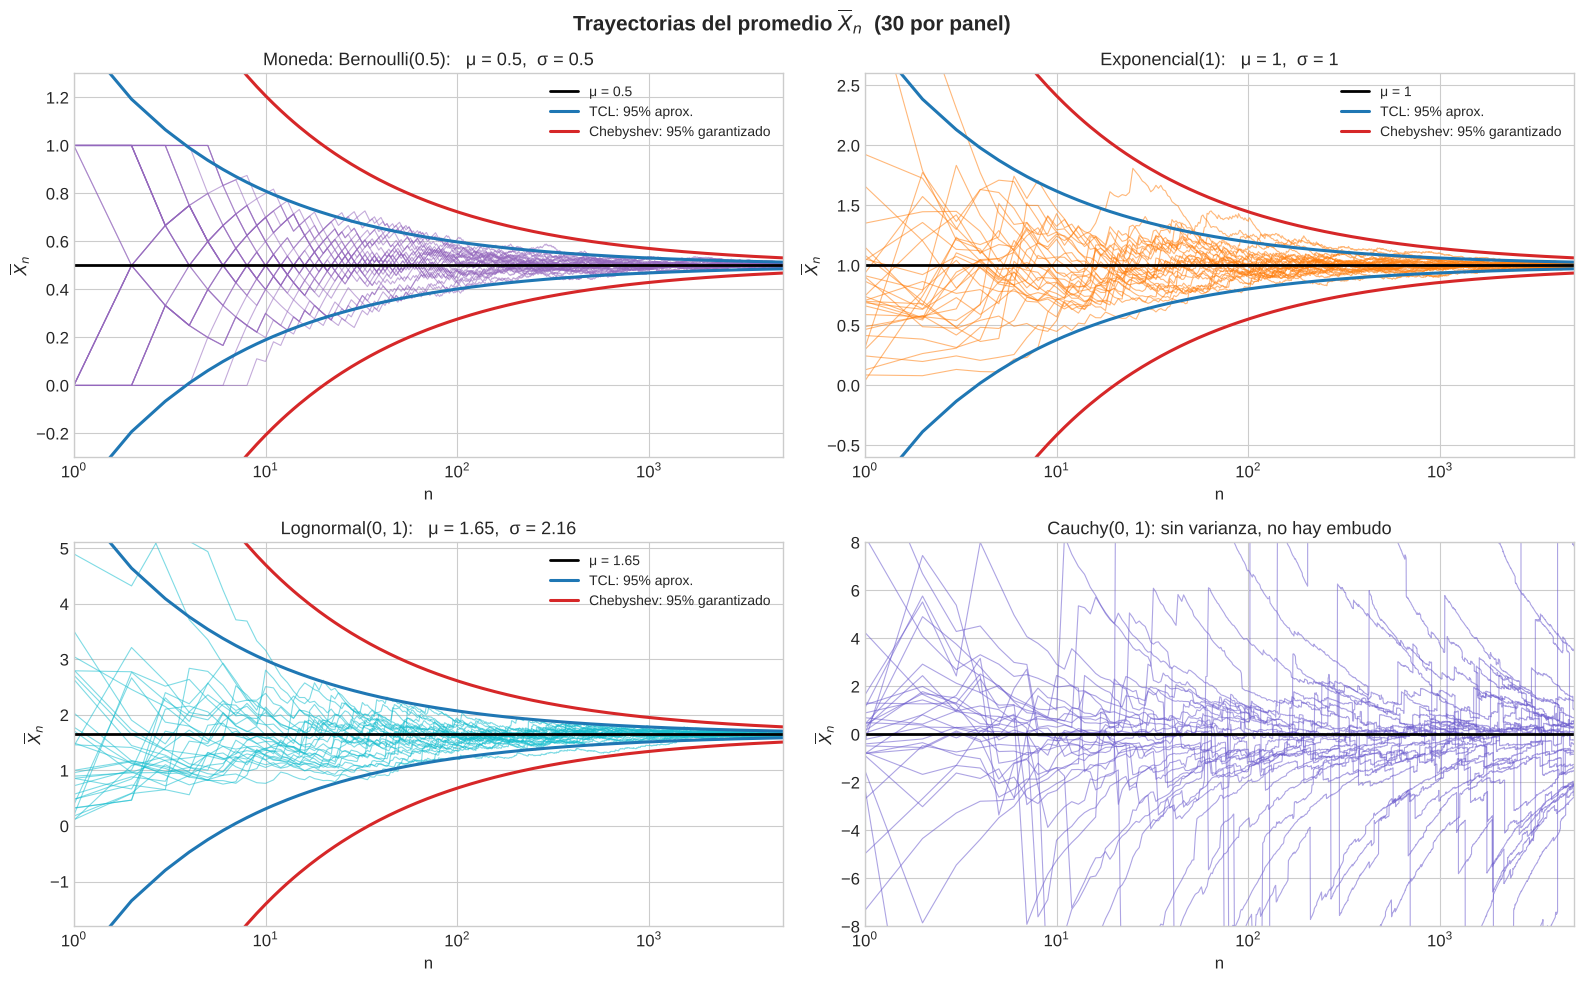

In [28]:
n_max, m = 5000, 30
n = np.arange(1, n_max + 1)
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
for ax, (nombre, (d, col)) in zip(axs.flat, DIST4.items()):
    T = trayectorias(d, n_max, m, semilla=7)
    ax.plot(n, T.T, color=col, lw=0.8, alpha=0.55)
    if nombre.startswith('Cauchy'):
        ax.axhline(0, color='black', lw=2)
        ax.set_ylim(-8, 8)
        ax.set_title(f'{nombre}: sin varianza, no hay embudo', fontsize=13)
    else:
        mu, s = d.mean(), d.std()
        ax.axhline(mu, color='black', lw=2, label=f'μ = {mu:.3g}')
        for k, c, etiqueta in [(1.96, COLORES['Normal'], 'TCL: 95% aprox.'),
                               (1 / np.sqrt(0.05), COLORES['Chebyshev'], 'Chebyshev: 95% garantizado')]:
            ax.plot(n, mu + k * s / np.sqrt(n), color=c, lw=2.2, label=etiqueta)
            ax.plot(n, mu - k * s / np.sqrt(n), color=c, lw=2.2)
        ax.set_ylim(mu - 1.6 * s, mu + 1.6 * s)
        ax.set_title(f'{nombre}:   μ = {mu:.3g},  σ = {s:.3g}', fontsize=13)
        ax.legend(loc='upper right', fontsize=10)
    ax.set_xscale('log'); ax.set_xlim(1, n_max)
    ax.set_xlabel('n'); ax.set_ylabel(r'$\overline{X}_n$')
fig.suptitle('Trayectorias del promedio $\\overline{X}_n$  (30 por panel)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Fijate que...
- En las tres primeras, las trayectorias **se encierran** alrededor de $\mu$ y el embudo del TCL describe muy bien su ancho: para cada $n$, casi todas quedan adentro del azul. El rojo, en cambio, queda **holgado**: es el precio de que Chebyshev valga para todo.
- Cada trayectoria es **muy errática al principio** y después se estabiliza: el valor de $\overline X_n$ para $n$ chico depende mucho de las primeras observaciones.
- En la **lognormal**, las trayectorias pegan **saltos hacia arriba** cada vez que aparece un valor muy grande, y bajan despacio. Se nota la cola larga: las trayectorias pasan más tiempo por debajo de $\mu$ que por encima.
- En la **Cauchy** las trayectorias **no se estabilizan nunca**: cada tanto aparece un valor enorme que patea el promedio. Lo vemos de cerca en 4.5.

### 4.3 ¿Qué fracción se escapa de $\mu \pm \varepsilon$?
La LGN habla de $P(|\overline X_n - \mu| \ge \varepsilon)$ para un $\varepsilon$ **fijo**. Si dibujamos la banda $\mu \pm \varepsilon$, esa probabilidad es la fracción de trayectorias que, en el paso $n$, están afuera.

Comparamos, para la moneda con $\varepsilon = 0.05$ y la exponencial con $\varepsilon = 0.1$:
- **Probabilidad real:** exacta (binomial y gamma).
- **Fracción simulada:** sobre 2000 trayectorias.
- **Cota de Chebyshev:** $\sigma^2 / (n \varepsilon^2)$.
- **Aproximación del TCL:** $2\big(1 - \Phi(\varepsilon\sqrt n / \sigma)\big)$.

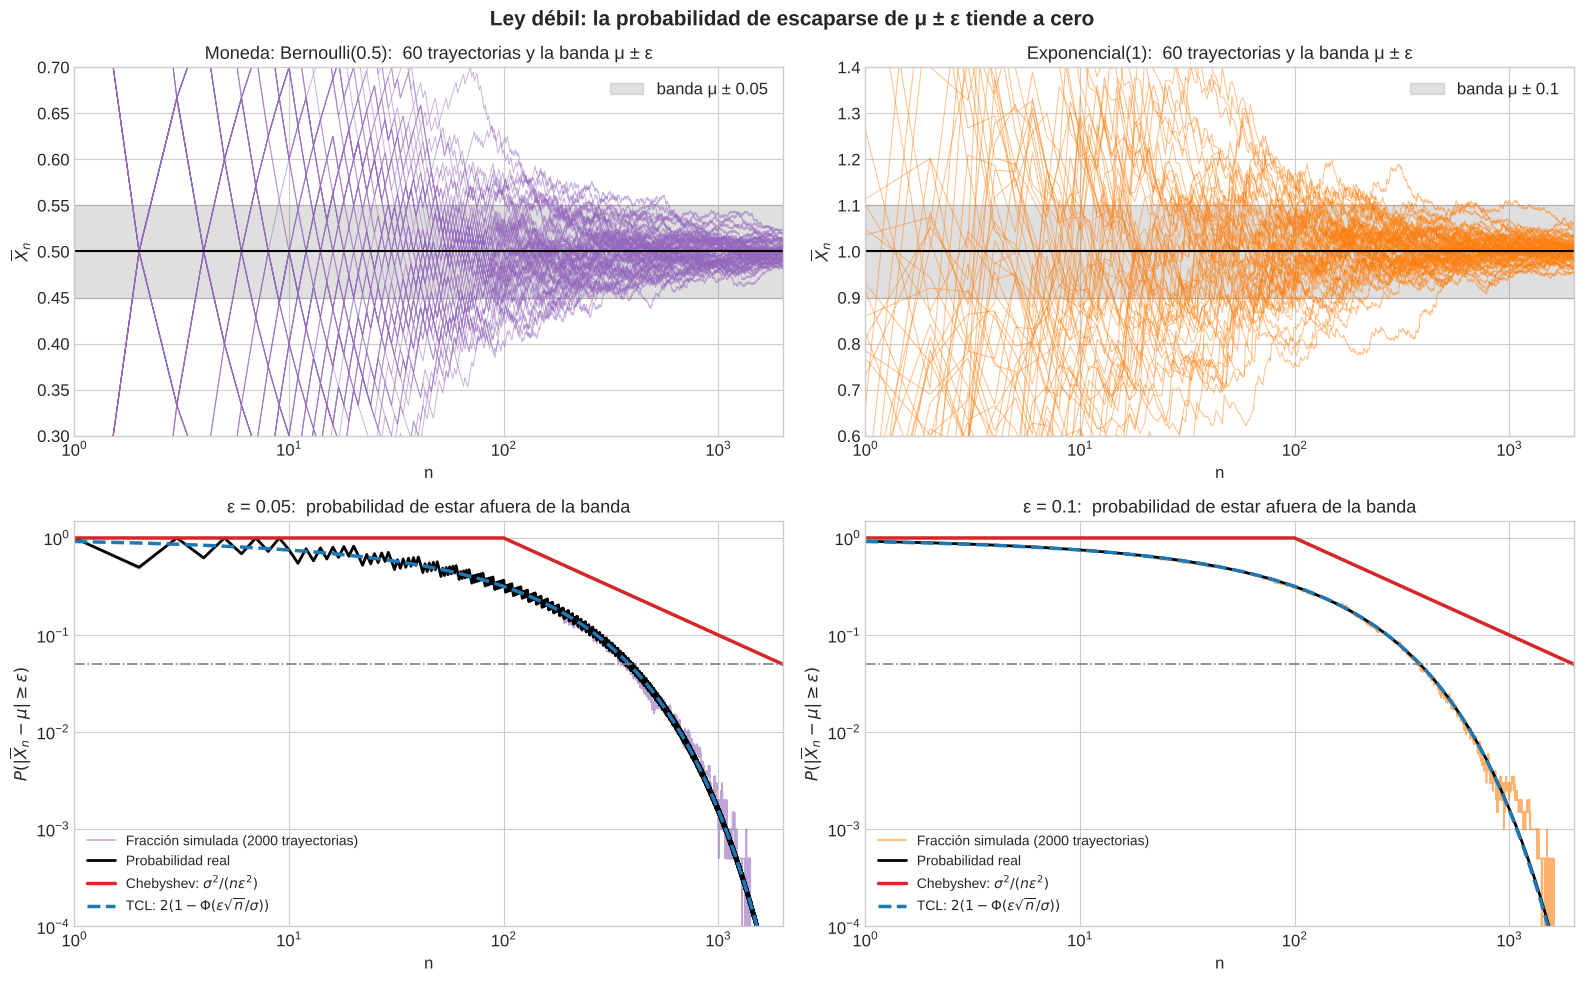

In [29]:
def p_real_escape(nombre, n, eps):
    n = np.asarray(n)
    if nombre.startswith('Moneda'):           # n * Xbar ~ Bin(n, 0.5)
        abajo = stats.binom.cdf(np.floor(n * (0.5 - eps) + 1e-9), n, 0.5)
        arriba = stats.binom.sf(np.ceil(n * (0.5 + eps) - 1e-9) - 1, n, 0.5)
        return abajo + arriba
    # Exponencial(1): Xbar ~ Gamma(n, escala 1/n)
    return stats.gamma.cdf(1 - eps, a=n, scale=1 / n) + stats.gamma.sf(1 + eps, a=n, scale=1 / n)

casos4 = [('Moneda: Bernoulli(0.5)', 0.05, 2000), ('Exponencial(1)', 0.1, 2000)]
fig, axs = plt.subplots(2, 2, figsize=(16, 10), gridspec_kw=dict(height_ratios=[1, 1.1]))
for j, (nombre, eps, n_max4) in enumerate(casos4):
    d, col = DIST4[nombre]
    mu, s = d.mean(), d.std()
    T = trayectorias(d, n_max4, 2000, semilla=11)
    nn = np.arange(1, n_max4 + 1)
    # Arriba: 60 trayectorias con la banda fija
    ax = axs[0, j]
    afuera_final = np.abs(T[:60, -1] - mu) >= eps
    ax.plot(nn, T[:60].T, color=col, lw=0.7, alpha=0.5)
    ax.axhspan(mu - eps, mu + eps, color='gray', alpha=0.25, label=f'banda μ ± {eps}')
    ax.axhline(mu, color='black', lw=1.5)
    ax.set_xscale('log'); ax.set_xlim(1, n_max4); ax.set_ylim(mu - 4 * eps, mu + 4 * eps)
    ax.set_xlabel('n'); ax.set_ylabel(r'$\overline{X}_n$'); ax.legend(loc='upper right')
    ax.set_title(f'{nombre}:  60 trayectorias y la banda μ ± ε', fontsize=13)
    # Abajo: fracción afuera vs cotas
    ax = axs[1, j]
    frac = np.mean(np.abs(T - mu) >= eps - 1e-12, axis=0)
    ax.plot(nn, frac, color=col, lw=1.2, alpha=0.6, label='Fracción simulada (2000 trayectorias)')
    ax.plot(nn, p_real_escape(nombre, nn, eps), color='black', lw=2, label='Probabilidad real')
    ax.plot(nn, np.minimum(1, s**2 / (nn * eps**2)), color=COLORES['Chebyshev'], lw=2.5,
            label=r'Chebyshev: $\sigma^2 / (n\varepsilon^2)$')
    ax.plot(nn, 2 * stats.norm.sf(eps * np.sqrt(nn) / s), color=COLORES['Normal'], lw=2.5, ls='--',
            label=r'TCL: $2(1-\Phi(\varepsilon\sqrt{n}/\sigma))$')
    ax.axhline(0.05, color='gray', ls='-.', lw=1.2)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-4, 1.5); ax.set_xlim(1, n_max4)
    ax.set_xlabel('n'); ax.set_ylabel(r'$P(|\overline{X}_n - \mu| \geq \varepsilon)$')
    ax.legend(loc='lower left', fontsize=10)
    ax.set_title(f'ε = {eps}:  probabilidad de estar afuera de la banda', fontsize=13)
fig.suptitle('Ley débil: la probabilidad de escaparse de μ ± ε tiende a cero', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- La fracción simulada sigue a la probabilidad real (negra), con el ruido propio de 2000 trayectorias.
- La cota de Chebyshev (roja) va a cero como $1/n$: es una recta de pendiente $-1$ en log-log. La probabilidad real cae **mucho más rápido**, del tipo $e^{-c\,n}$. Para $n$ grande la diferencia es de **varios órdenes de magnitud**.
- La aproximación del TCL (azul) acompaña muy bien a la probabilidad real, incluso en la exponencial. En la Parte 3 vimos que cada cola por separado se equivoca, pero acá sumamos las dos colas y los errores se compensan.
- En la moneda la probabilidad real zigzaguea: $n\overline X_n$ es entero, y la condición $|\overline X_n - 0.5| \ge \varepsilon$ cambia a saltos.

### 4.4 El ejemplo de la Clase 17: ¿cuántas mediciones hacen falta?
En la Clase 17 planteamos: cada medición tiene $\sigma = 0.5$, distribución desconocida. ¿Cuántas mediciones $n$ hacen falta para que
$$
P\big(|\overline X_n - \mu| \ge 0.1\big) \le 0.05\ ?
$$

| Herramienta | Cuenta | $n$ necesario |
|---|---|---|
| Chebyshev | $\dfrac{0.25}{0.01\,n} \le 0.05$ | $n \ge 500$ |
| TCL | $2\big(1 - \Phi(0.1\sqrt n / 0.5)\big) \le 0.05 \iff \sqrt n \ge \dfrac{1.96 \cdot 0.5}{0.1}$ | $n \ge 97$ |

Pero la distribución **real** importa. Tomamos cinco distribuciones distintas, todas reescaladas para tener $\sigma = 0.5$, y buscamos el menor $n$ a partir del cual la probabilidad real queda por debajo de $0.05$.

In [30]:
SIGMA, EPS, ALFA = 0.5, 0.1, 0.05
N_MAX = 400

def escalar(d):
    # transforma d para que tenga media 0 y desvío SIGMA (la probabilidad buscada no depende de mu)
    return lambda size, rng: (d.rvs(size=size, random_state=rng) - d.mean()) / d.std() * SIGMA

def prob_simulada(muestreador, reps=100_000, bloque=5_000, semilla=3):
    # estima P(|Xbar_n| >= EPS) para n = 1..N_MAX recorriendo trayectorias por bloques
    rng = np.random.default_rng(semilla)
    cuentas = np.zeros(N_MAX)
    nn = np.arange(1, N_MAX + 1)
    for _ in range(reps // bloque):
        Xbar = np.cumsum(muestreador((bloque, N_MAX), rng), axis=1) / nn
        cuentas += np.sum(np.abs(Xbar) >= EPS, axis=0)
    return cuentas / reps

nn = np.arange(1, N_MAX + 1)
PROB = {
    'Normal':          2 * stats.norm.sf(EPS * np.sqrt(nn) / SIGMA),                 # exacta
    'Moneda (p = 0.5)': stats.binom.cdf(np.floor(nn * (0.5 - EPS) + 1e-9), nn, 0.5)          # sigma = 0.5 sin reescalar
                       + stats.binom.sf(np.ceil(nn * (0.5 + EPS) - 1e-9) - 1, nn, 0.5),       # exacta
    'Exponencial':     stats.gamma.cdf(SIGMA - EPS, a=nn, scale=SIGMA / nn)
                       + stats.gamma.sf(SIGMA + EPS, a=nn, scale=SIGMA / nn),          # exacta
    'Uniforme':        prob_simulada(escalar(stats.uniform())),
    'Lognormal':       prob_simulada(escalar(stats.lognorm(s=1))),
}

def n_minimo(p):
    for i in range(len(p)):
        if np.all(p[i:] <= ALFA):
            return int(nn[i])
    return None

n_cheb = int(np.ceil(SIGMA**2 / (ALFA * EPS**2)))
n_tcl = int(np.ceil((stats.norm.isf(ALFA / 2) * SIGMA / EPS)**2))
filas = [{'Distribución': k, 'n mínimo real': n_minimo(v) if n_minimo(v) else f'> {N_MAX}',
          f'Probabilidad real en n = {n_tcl}': v[n_tcl - 1]} for k, v in PROB.items()]
tabla4 = pd.DataFrame(filas).set_index('Distribución')
print(f'Chebyshev pide n ≥ {n_cheb};  el TCL pide n ≥ {n_tcl}.')
display(tabla4.style.format({f'Probabilidad real en n = {n_tcl}': '{:.4f}'})
        .set_caption('Menor n desde el cual P(|X̄ − μ| ≥ 0.1) ≤ 0.05, con σ = 0.5'))

Chebyshev pide n ≥ 500;  el TCL pide n ≥ 97.


,n mínimo real,Probabilidad real en n = 97
Distribución,,
Normal,97,0.0489
Moneda (p = 0.5),106,0.0417
Exponencial,96,0.0483
Uniforme,97,0.0498
Lognormal,93,0.0463


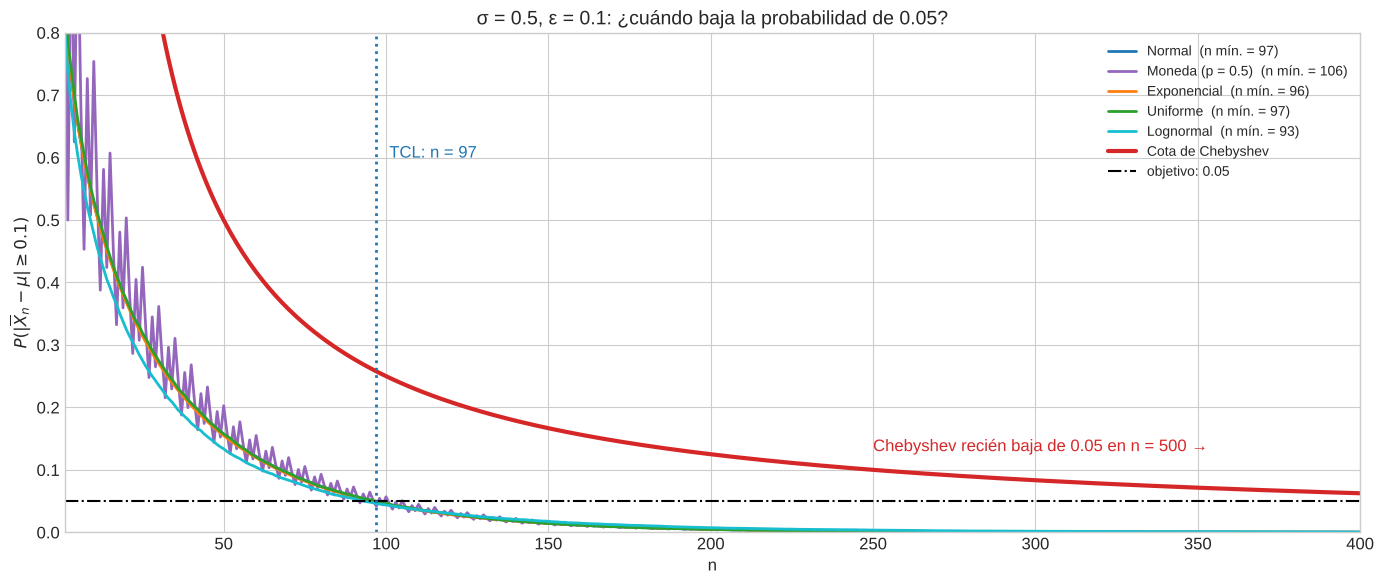

In [31]:
fig, ax = plt.subplots(figsize=(14, 6))
estilos = {'Normal': (COLORES['Normal'], '-'), 'Moneda (p = 0.5)': (COLORES['Binomial'], '-'),
           'Exponencial': (COLORES['Exponencial'], '-'), 'Uniforme': (COLORES['Uniforme'], '-'),
           'Lognormal': (COLORES['Lognormal'], '-')}
for nombre, p in PROB.items():
    col, ls = estilos[nombre]
    ax.plot(nn, p, color=col, ls=ls, lw=2, label=f'{nombre}  (n mín. = {n_minimo(p)})')
ax.plot(nn, np.minimum(1, SIGMA**2 / (nn * EPS**2)), color=COLORES['Chebyshev'], lw=3, label='Cota de Chebyshev')
ax.axhline(ALFA, color='black', ls='-.', lw=1.5, label='objetivo: 0.05')
ax.axvline(n_tcl, color=COLORES['Normal'], ls=':', lw=2)
ax.text(n_tcl + 4, 0.6, f'TCL: n = {n_tcl}', color=COLORES['Normal'], fontsize=12)
ax.text(250, 0.13, f'Chebyshev recién baja de 0.05 en n = {n_cheb} →', color=COLORES['Chebyshev'], fontsize=12)
ax.set_xlim(1, N_MAX); ax.set_ylim(0, 0.8)
ax.set_xlabel('n'); ax.set_ylabel(r'$P(|\overline{X}_n - \mu| \geq 0.1)$')
ax.legend(loc='upper right', fontsize=10)
ax.set_title('σ = 0.5, ε = 0.1: ¿cuándo baja la probabilidad de 0.05?', fontsize=14)
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- Para **todas** las distribuciones, el $n$ real queda **cerca del que da el TCL** y muy lejos de los 500 de Chebyshev. La moneda pide un poco más (106) porque es discreta: su probabilidad zigzaguea y tarda en quedarse definitivamente por debajo de 0.05.
- Las diferencias entre distribuciones son chicas: con $n \approx 100$ ya estamos en la zona donde el TCL funciona bien para la probabilidad de **dos colas juntas**. En la Parte 3 vimos que cada cola por separado se equivoca más, pero los errores en una y otra cola se compensan en parte.
- **Moraleja práctica:** Chebyshev da una **garantía** (500 alcanzan siempre, sea cual sea la distribución); el TCL da una **estimación** mucho más ajustada que, para un problema como este, resulta acertada.

### 4.5 La Cauchy: un promedio que no converge
Ya vimos en la Parte 3 que el promedio de $n$ Cauchy es otra vez Cauchy. Mirado en trayectorias, eso se traduce en **saltos que no desaparecen nunca**: cada tanto aparece una observación enorme y desplaza el promedio, sin importar cuántas observaciones lleves.

Como contraste graficamos también la **mediana acumulada**: la mediana de las primeras $n$ observaciones. Esa sí converge a 0, porque no le importan los valores extremos.

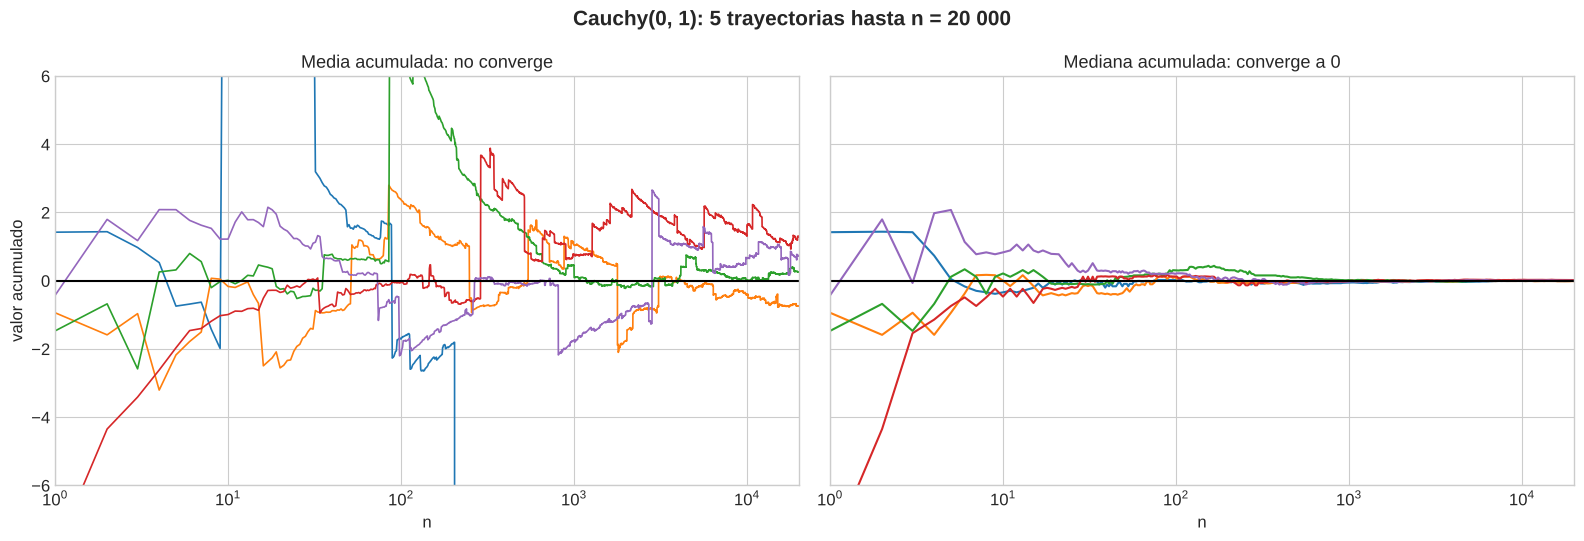

In [32]:
n_max_c = 20_000
rng_c = np.random.default_rng(5)
X = stats.cauchy.rvs(size=(5, n_max_c), random_state=rng_c)
nn_c = np.arange(1, n_max_c + 1)
medias = np.cumsum(X, axis=1) / nn_c
puntos = np.unique(np.round(np.geomspace(1, n_max_c, 400)).astype(int))
medianas = np.array([[np.median(X[i, :k]) for k in puntos] for i in range(5)])
tonos = plt.cm.tab10(np.arange(5))
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for i in range(5):
    axs[0].plot(nn_c, medias[i], color=tonos[i], lw=1.2)
    axs[1].plot(puntos, medianas[i], color=tonos[i], lw=1.5)
for ax, titulo in zip(axs, ['Media acumulada: no converge', 'Mediana acumulada: converge a 0']):
    ax.axhline(0, color='black', lw=1.5)
    ax.set_xscale('log'); ax.set_xlim(1, n_max_c); ax.set_ylim(-6, 6)
    ax.set_xlabel('n'); ax.set_title(titulo, fontsize=13)
axs[0].set_ylabel('valor acumulado')
fig.suptitle('Cauchy(0, 1): 5 trayectorias hasta n = 20 000', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

#### 🔎 Lectura
- A la izquierda, las trayectorias de la media siguen dando **saltos de tamaño comparable** con $n = 10$ que con $n = 10\,000$. No hay embudo.
- A la derecha, las mismas observaciones resumidas con la **mediana** sí se encierran alrededor de 0.
- La LGN necesita $E|X| < \infty$ (y la versión que demostramos, $\sigma^2 < \infty$). Cuando falla, el promedio deja de ser un buen resumen. Es un adelanto de un tema de la Unidad 6: **elegir el estimador** depende de la distribución.

### 4.6 🎛️ Explorá vos
Elegí la distribución, cuántas trayectorias, hasta qué $n$ y el ancho $\varepsilon$ de la banda.
- **Izquierda:** las trayectorias, la banda $\mu \pm \varepsilon$ y, si querés, los embudos del TCL y de Chebyshev.
- **Derecha:** la fracción de trayectorias fuera de la banda para cada $n$, contra la cota de Chebyshev y la aproximación del TCL.

**Para probar:**
- Moneda con $\varepsilon = 0.01$: ¿cuánto hay que esperar para que casi ninguna trayectoria se escape?
- Lognormal con 200 trayectorias: mirá los saltos y hacia qué lado se escapan.
- Cauchy con $n$ hasta 5000: la fracción afuera no baja.

In [33]:
def lab_lgn(familia, m, n_max, eps, embudos):
    d, col = DIST4[familia]
    T = trayectorias(d, n_max, m, semilla=int(eps * 1000) + m)
    nn = np.arange(1, n_max + 1)
    es_cauchy = familia.startswith('Cauchy')
    mu = 0.0 if es_cauchy else d.mean()
    fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
    ax = axs[0]
    ax.plot(nn, T[:min(m, 100)].T, color=col, lw=0.7, alpha=0.5)
    ax.axhspan(mu - eps, mu + eps, color='gray', alpha=0.25, label=f'banda μ ± {eps:g}')
    ax.axhline(mu, color='black', lw=1.5)
    if embudos and not es_cauchy:
        s = d.std()
        for k, c, et in [(1.96, COLORES['Normal'], 'TCL 95%'), (1 / np.sqrt(0.05), COLORES['Chebyshev'], 'Chebyshev 95%')]:
            ax.plot(nn, mu + k * s / np.sqrt(nn), color=c, lw=2, label=et)
            ax.plot(nn, mu - k * s / np.sqrt(nn), color=c, lw=2)
    escala = 3 if es_cauchy else max(4 * eps, 1.2 * d.std())
    ax.set_ylim(mu - escala, mu + escala)
    ax.set_xscale('log'); ax.set_xlim(1, n_max); ax.set_xlabel('n'); ax.set_ylabel(r'$\overline{X}_n$')
    ax.legend(loc='upper right', fontsize=10)
    ax.set_title(f'{familia}: {min(m, 100)} de {m} trayectorias', fontsize=13)
    ax = axs[1]
    frac = np.mean(np.abs(T - mu) >= eps, axis=0)
    ax.plot(nn, frac, color=col, lw=1.5, label='Fracción afuera (simulada)')
    if not es_cauchy:
        s = d.std()
        ax.plot(nn, np.minimum(1, s**2 / (nn * eps**2)), color=COLORES['Chebyshev'], lw=2.5, label='Chebyshev')
        ax.plot(nn, 2 * stats.norm.sf(eps * np.sqrt(nn) / s), color=COLORES['Normal'], lw=2.5, ls='--', label='TCL')
    else:
        p_c = 1 - 2 / np.pi * np.arctan(eps)
        ax.axhline(p_c, color='black', lw=2, ls='--', label=f'P(|Cauchy| ≥ ε) = {p_c:.3f}, para todo n')
    ax.set_xscale('log'); ax.set_xlim(1, n_max); ax.set_ylim(0, 1.02)
    ax.set_xlabel('n'); ax.set_ylabel(r'$P(|\overline{X}_n - \mu| \geq \varepsilon)$')
    ax.legend(loc='lower left' if es_cauchy else 'center right', fontsize=10)
    ax.set_title(f'En n = {n_max}: {frac[-1]:.1%} de las trayectorias afuera', fontsize=13)
    plt.tight_layout()
    plt.show()

w_fam4 = widgets.Dropdown(options=list(DIST4.keys()), value='Moneda: Bernoulli(0.5)', description='Partida')
w_m4   = widgets.IntSlider(value=200, min=10, max=2000, step=10, description='trayect.', continuous_update=False)
w_n4   = widgets.IntSlider(value=2000, min=50, max=20000, step=50, description='n máx.', continuous_update=False)
w_eps4 = widgets.FloatLogSlider(value=0.05, base=10, min=-2.5, max=0, step=0.05, description='ε',
                                readout_format='.3f', continuous_update=False)
w_emb4 = widgets.Checkbox(value=True, description='Mostrar embudos')
salida4 = widgets.interactive_output(lab_lgn, dict(familia=w_fam4, m=w_m4, n_max=w_n4, eps=w_eps4, embudos=w_emb4))
display(widgets.VBox([widgets.HBox([w_fam4, w_m4, w_n4]), widgets.HBox([w_eps4, w_emb4]), salida4]))

### 4.7 Para cerrar la Parte 4 (y el notebook)
- Cada trayectoria de $\overline X_n$ es errática al principio y se va encerrando alrededor de $\mu$. El ancho del encierro es del orden de $\sigma/\sqrt n$, como dice el TCL.
- La LGN dice que la fracción de trayectorias fuera de $\mu \pm \varepsilon$ tiende a cero. Chebyshev la acota por $\sigma^2/(n\varepsilon^2)$; la probabilidad real cae mucho más rápido.
- En el ejemplo de la Clase 17, Chebyshev pide $n = 500$, el TCL pide $n = 97$, y el valor real, para distribuciones muy distintas, queda cerca de 97.
- Sin varianza finita la historia cambia: con la Cauchy el promedio no converge, pero la mediana sí.

**Un hilo que recorre todo el notebook:** Chebyshev, la regla $np \ge 5$, la regla $n \ge 30$ y Berry–Esseen son todas formas de responder la misma pregunta: **¿cuánto me equivoco si uso una aproximación?** Las cotas universales (Chebyshev, Berry–Esseen) garantizan, pero son pesimistas. Las reglas prácticas ($np \ge 5$, $n \ge 30$) son optimistas, y fallan en las colas y con distribuciones asimétricas.

**Preguntas para pensar**
1. Una encuesta quiere estimar una proporción $p$ con error menor a $0.03$ con probabilidad $0.95$. ¿Qué $n$ da Chebyshev en el peor caso ($p = 0.5$)? ¿Y el TCL?
2. En 4.3, la cota de Chebyshev cae como $1/n$ y la probabilidad real como $e^{-cn}$. ¿Qué información sobre $X$ usa Chebyshev, y cuál le falta para "ver" la caída exponencial?
3. ¿Por qué la mediana de la Cauchy converge y la media no? Pensá qué pasa con cada una si una sola observación se va a $+\infty$.